<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QAE_FederatedAnomalyDetection_Chaudhary2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum federated autoencoder for IoT anomaly detection: Chaudhary, Rajasegarar and Pokhrel (2026) step by step

> **READ THIS FIRST: the paper's data are private, so this notebook runs on a public substitute.**
> The authors measured their own Raspberry Pi 3B+ / XBee ZigBee testbed (5 h of normal traffic for training, 1 h for validation,
> redirection attacks launched with AT commands). Those captures are not released. The method itself is fully specified, so this
> notebook re-implements it and runs it on **N-BaIoT** (Meidan et al., 2018, UCI repository #442): real traffic of nine commercial
> IoT devices, benign and under BASHLITE and Mirai attacks. The three federated clients are three groups of three real devices.
> The numbers of the paper's Table II are shown next to ours, but **every claim that depends on the private testbed is marked
> "cannot be checked"**; what can be tested on the substitute are the method-level claims (federated training matches centralised
> training, hierarchical versus canonical aggregation, convergence of the loss).

This notebook re-implements, runs and checks the method of

> Devashish Chaudhary, Sutharshan Rajasegarar and Shiva Raj Pokhrel, "Modeling Quantum Federated Autoencoder for Anomaly
> Detection in IoT Networks", *2026 International Conference on Information Networking (ICOIN)*, IEEE, 2026,
> DOI 10.1109/ICOIN68469.2026.11480492 (arXiv:2603.22366).

The paper publishes no code. Everything below is written from the five-page description, with the software stack it names
(Qiskit on a quantum simulator, COBYLA, scikit-learn style preprocessing).

**What the notebook does.**
1. Downloads the N-BaIoT archive (1.7 GB, UCI), keeps a small seeded sample of every device and deletes the archive.
2. Builds three "routers" R1, R2, R3 (three real devices each); trains on **benign traffic only**, tests on benign plus attack traffic, as in the paper.
3. Preprocesses with MinMax scaling and PCA to 10 components (fitted on the training split only) and encodes the components as RY angles on 10 qubits.
4. Trains a **quantum autoencoder** (8 latent + 2 trash qubits, RealAmplitudes encoder, trash-qubit loss of Eq. 1, COBYLA) in four ways: hierarchical federated learning, canonical FedAvg, no federation, and centralised training.
5. Sets the threshold tau = mu - 4 sigma on the validation fidelities and classifies a test sample as an anomaly when its fidelity is below tau.
6. Trains classical references (autoencoder, one-class SVM, Isolation Forest, random forest, SVC) on the identical inputs.
7. Draws the executed circuits, redraws the paper's loss curves (Fig. 4), and compares Table II with our numbers, claim by claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. The first run downloads and samples
the archive (about 10-20 minutes, mostly network and unpacking); after that the `FAST_MODE = True` path trains in a few minutes.
`FAST_MODE = False` uses more seeds and larger samples. No Hugging Face token is needed (the data come from the UCI repository).

**What you get at the end.** Per-router accuracy / precision / recall / F1 for the four training modes (mean +- std over seeds), the
classical references, the paper's Table II side by side, a verdict per claim, and a critical reading of the paper.

## The paper in one page

**Problem.** Detect anomalies (here: redirection attacks) in the traffic of a hierarchical IoT network without sending raw traffic to a
server. Classical deep-learning detectors are centralised; federated learning (FL) keeps the data on the routers, and the authors
make the local model a **quantum autoencoder (QAE)**.

**Decision.** For every one-minute window of traffic features, the QAE gives a *reconstruction fidelity*; windows whose fidelity is
below tau = mu - 4 sigma (mu, sigma = mean and standard deviation of the fidelities on the benign validation set) are anomalies.

**Method (Fig. 1, Algorithm 1).**
- 31 traffic features per window (mean and first-hop delay, delay quartiles, Shannon entropy, communication counts, hops) -> MinMax -> PCA to 10 components.
- 10 qubits = 8 latent + 2 trash. The 10 components are RY angles. A **RealAmplitudes** circuit is the encoder `U(theta)`.
- A QAE cannot discard qubits, so training pushes the *trash* qubits to `|0>`. The cost (Eq. 1) is the batch mean of the total probability of all non-zero trash outcomes.
- Optimiser COBYLA, **50 iterations per client and round** (federated) or **100 iterations** (centralised). **3 routers, 5 rounds**; every router's training set is split into 5 subsets, one per round.
- Aggregation: canonical **FedAvg** or **hierarchical FL** (children combined at their parent first, Fig. 1 and 3), compared with a centralised baseline that pools and shuffles the data of all routers.

**Data (Section IV).** Private testbed with Raspberry Pi 3B+ and XBee S2C ZigBee modules; normal traffic for 5 h (train) + 1 h (validation);
attack sessions of 20 min normal + 5 min attack + 10 min normal; three attack scenarios (Table I).

**Claims.** Table II: accuracy, precision, recall, F1 per router; federated learning is "on par with or exceeding" centralised training
(R1 FedAvg 0.93 > hierarchical 0.91 > centralised 0.88; R2 all 0.91; R3 hierarchical and centralised 0.99 > FedAvg 0.94); the loss converges smoothly (Fig. 4).
Table II has **recall = accuracy in every row**, which is what scikit-learn's *weighted* averaging gives, so we report weighted precision / recall / F1.

**What the paper does not say** (and we had to choose): RealAmplitudes repetitions and entanglement, shots, initial parameters,
COBYLA settings, the exact hierarchical averaging rule, how the "reconstruction fidelity" is computed from the trash measurement,
which validation set each router uses, and whether PCA is fitted locally or globally. No code, no data.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| **Data** | **Private Raspberry Pi / XBee ZigBee testbed, 31 features per one-minute window** | **SUBSTITUTE: N-BaIoT (UCI #442), nine real IoT devices, 115 features per record, benign + BASHLITE + Mirai** |
| Clients | 3 routers R1-R3 of the testbed | 3 groups of 3 real devices (R1: 2 doorbells + thermostat, R2: baby monitor + 2 Provision cameras, R3: Samsung webcam + 2 SimpleHome cameras) |
| Training data | 5 h of normal traffic (about 300 windows) | benign rows only, `N_TRAIN_PER_CLIENT` per router, time-ordered split of each device: first 60 % train, next 15 % validation, last 25 % test |
| Attacks | redirection via ZigBee AT commands (Table I), 5 min per 35 min session | the 10 attack types of N-BaIoT, 1 attack row per 6 normal rows in the test set (the 5 : 30 min ratio of a session) |
| Features / PCA | 31 -> MinMax -> PCA 10 (fitted on training data) | 115 -> MinMax -> PCA 10 (fitted on training data, locally per router: `PCA_SCOPE = "local"`) -> MinMax to [0, pi] (angles, test angles clipped) |
| Qubits | 10 (8 latent + 2 trash) | the same; trash = qubits 8 and 9 |
| Encoding | RY angle encoding | the same, one component per qubit |
| Encoder | RealAmplitudes, repetitions not stated | `REPS = 2` (30 trainable angles), Qiskit default `reverse_linear` entanglement |
| Loss | Eq. (1), mean probability of non-zero trash outcomes | the same, computed exactly (no shot noise); Aer shot-based check shown |
| Optimiser | COBYLA, 50 iterations (FL), 100 (centralised) | SciPy COBYLA (what Qiskit's COBYLA wraps), `maxiter` = 50 / 100 function evaluations, `rhobeg = 1` |
| Initial parameters | not stated | U(-pi, pi), the same initial point for all four training modes of a seed |
| Federated protocol | 3 clients, 5 rounds, training set split in 5 subsets | the same; every round a client starts from the global parameters |
| FedAvg | canonical | mean weighted by number of rows (equal sizes, so a plain mean) |
| Hierarchical FL | "child nodes are combined at parent nodes before forming a global model" | Table I Scenario I tree R3 -> R2 -> C and R1 -> C: R2' = mean(R2, R3), global = mean(R1, R2'); weights 1/2, 1/4, 1/4 |
| Fidelity | "reconstruction fidelity" | P(trash = 00); shown to equal the fidelity of compress - reset trash - decompress |
| Threshold | tau = mu - 4 sigma on validation fidelities | the same, using each router's own benign validation rows |
| Centralised model | pooled and shuffled data of all routers | the same, pooled MinMax + PCA, whole pooled set per COBYLA evaluation |
| Metrics | accuracy, precision, recall, F1 (recall = accuracy) | the same, weighted average; plus attack recall, false-alarm rate, AUROC |
| Repeats | one run | `N_SEEDS` seeds (data draw, initial point, round partition), mean +- std |
| Hardware | Apple M2, Python 3.11.7 | any CPU; Colab CPU is enough |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc
    print("Qiskit installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit and qiskit-aer already present; skipping pip install.")

qiskit and qiskit-aer already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
import numpy as np
SEED = 42
FAST_MODE = False           # True: about 10 minutes (2 seeds, small sample sizes). False: 5 seeds, larger samples.
IBM_TOKEN = ""              # not used: the paper simulates its circuit (Qiskit simulator) and so do we

# ---- what the paper fixes (Section IV-A, Algorithm 1) ----
N_QUBITS = 10               # 10 qubits ...
N_TRASH = 2                 # ... = 8 latent + 2 trash
PCA_DIM = 10                # PCA to 10 components, one component per qubit
N_CLIENTS = 3               # routers R1, R2, R3
ROUNDS = 5                  # federated rounds
LOCAL_ITERS = 50            # COBYLA iterations per client per round (federated)
CENTRAL_ITERS = 100         # COBYLA iterations (centralised)
TAU_SIGMAS = 4              # threshold tau = mu - 4 sigma of the validation fidelities

# ---- what the paper leaves open (CHOICE: ...) ----
REPS = 2                    # CHOICE: RealAmplitudes repetitions (paper: not stated) -> 30 trainable angles
ENTANGLEMENT = "reverse_linear"   # CHOICE: Qiskit's default entanglement of RealAmplitudes
INIT_RANGE = (-np.pi, np.pi)   # CHOICE: initial angles ~ U(-pi, pi)
RHOBEG = 1.0                # CHOICE: initial COBYLA trust-region radius (SciPy default)
PCA_SCOPE = "local"         # CHOICE: "local" = every router fits MinMax+PCA on its own training data (features are
                            #         "computed locally at each router"); "global" = one pooled preprocessor for all
TOPOLOGY = {"C": ["R1", "R2"], "R2": ["R3"]}   # Table I, Scenario I normal traffic: R1->C, R2->C, R3->R2
ATTACK_TO_NORMAL = 5 / 30   # test sessions: 20 + 10 min normal vs 5 min attack (Section IV) -> 1 attack per 6 normal
TRAIN_FRAC, VAL_FRAC = 0.60, 0.15   # CHOICE: time-ordered split of each device's benign traffic: 60 % train, 15 % val, 25 % test

# ---- data and sample sizes (the paper's testbed has about 300 one-minute windows per router for training) ----
N_SEEDS = 2 if FAST_MODE else 5
N_TRAIN_PER_CLIENT = 150 if FAST_MODE else 300      # benign training rows per router (split into ROUNDS subsets)
N_VAL_PER_CLIENT = 150 if FAST_MODE else 300        # benign validation rows per router (threshold)
N_TEST_BENIGN_PER_CLIENT = 300 if FAST_MODE else 600
N_ATTACK_TRAIN_PER_CLIENT = 60 if FAST_MODE else 120  # attack rows used ONLY by the supervised reference classifiers
POOL_BENIGN = 2400          # benign rows kept per device (evenly spaced in time) out of the full archive
POOL_ATTACK_PER_TYPE = 120  # attack rows kept per device and attack type
CLIENT_DEVICES = {          # CHOICE: three routers = three groups of three real N-BaIoT devices (by device type)
    "R1": ["Danmini_Doorbell", "Ennio_Doorbell", "Ecobee_Thermostat"],
    "R2": ["Philips_B120N10_Baby_Monitor", "Provision_PT_737E_Security_Camera", "Provision_PT_838_Security_Camera"],
    "R3": ["Samsung_SNH_1011_N_Webcam", "SimpleHome_XCS7_1002_WHT_Security_Camera", "SimpleHome_XCS7_1003_WHT_Security_Camera"],
}
DEVICES = [d for ds in CLIENT_DEVICES.values() for d in ds]
CLIENTS = list(CLIENT_DEVICES)
DATA_DIR = "data_qc091"     # cache for the 1.7 GB archive (deleted after sampling) and the small pool file
ZIP_PATH = ""               # set to the path of an already downloaded N-BaIoT zip to skip the download
DELETE_ARCHIVE_AFTER_SAMPLING = True
RUN_PCA_SCOPE_ABLATION = not FAST_MODE   # extra table: PCA_SCOPE "global" instead of "local"
print(f"FAST_MODE={FAST_MODE}  seeds={N_SEEDS}  train/val/test-benign per router = "
      f"{N_TRAIN_PER_CLIENT}/{N_VAL_PER_CLIENT}/{N_TEST_BENIGN_PER_CLIENT}")

FAST_MODE=False  seeds=5  train/val/test-benign per router = 300/300/600


In [3]:
import os, sys, math, time, warnings, itertools, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import scipy
from scipy.optimize import minimize
import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC, OneClassSVM
from sklearn.neural_network import MLPRegressor
import qiskit, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

warnings.filterwarnings("ignore")
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | qiskit 2.5.2 | qiskit-aer 0.17.2


## 1. The substitute data: N-BaIoT

N-BaIoT (Meidan et al., *IEEE Pervasive Computing* 2018) captured the network traffic of nine commercial IoT devices (doorbells,
a thermostat, a baby monitor, webcams and security cameras) in a lab, first benign and then while the devices were infected with the
**BASHLITE (gafgyt)** and **Mirai** botnets. Every record has 115 statistical features of the last packets seen on the device's stream
(5 stream types x 5 decay time windows x statistics). Each device has its own `benign_traffic.csv` in capture order (a time series) and
one RAR archive per botnet with the individual attacks (`combo, junk, scan, tcp, udp` for BASHLITE; `ack, scan, syn, udp, udpplain` for Mirai).
Ennio Doorbell and Samsung Webcam have no Mirai capture.

**Why it is a fair substitute.** The paper's setting is "one model per router, trained on normal traffic only, tested on normal plus
attack traffic, data stay local". N-BaIoT is the public IoT data set with a *natural per-device partition*, so a federated client is a
real device group, not a random shard. It does **not** contain ZigBee redirection attacks, so absolute numbers cannot be compared
with the paper's, only the method-level behaviour.

**Download.** The archive (1.7 GB, CC BY 4.0) is fetched from the UCI repository; the Hugging Face copy `codymlewis/nbaiot` is only a loading
script for the very same file. The notebook unpacks one device at a time, keeps `POOL_BENIGN` benign rows (evenly spaced in capture time, so
the order is preserved) and `POOL_ATTACK_PER_TYPE` random rows of every attack type, stores the 31,200-row pool (about 8 MB) in `DATA_DIR`
and deletes the big files. The RAR files need `unrar`, 7-Zip or WinRAR; on Colab the cell installs `unrar` with `apt-get` if none is found.
Set `ZIP_PATH` to use an archive you already have. (The RAR extraction is the slow part; the pool is cached, so later runs skip it.)

In [4]:
import io, os, shutil, subprocess, tempfile, zipfile, time, glob
import requests

UCI_URL = "https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip"
os.makedirs(DATA_DIR, exist_ok=True)
POOL_FILE = os.path.join(DATA_DIR, f"nbaiot_pool_b{POOL_BENIGN}_a{POOL_ATTACK_PER_TYPE}_s{SEED}.npz")


def download_zip(dest):
    """Download the UCI N-BaIoT archive (about 1.7 GB) unless it is already there (CHOICE: or ZIP_PATH given)."""
    if ZIP_PATH and os.path.exists(ZIP_PATH):
        return ZIP_PATH
    if os.path.exists(dest) and os.path.getsize(dest) > 1.5e9:
        return dest
    print("downloading", UCI_URL)
    t0 = time.time()
    with requests.get(UCI_URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest + ".part", "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 22):
                f.write(chunk)
    os.replace(dest + ".part", dest)
    print(f"done in {time.time()-t0:.0f}s, {os.path.getsize(dest)/1e9:.2f} GB")
    return dest


def find_rar_tool():
    for name in ["unrar", "UnRAR", "7z", "7za", "7zz", "bsdtar"]:
        p = shutil.which(name)
        if p:
            return name, p
    for p in [r"C:\Program Files\WinRAR\UnRAR.exe", r"C:\Program Files (x86)\WinRAR\UnRAR.exe", r"C:\Program Files\7-Zip\7z.exe"]:
        if os.path.exists(p):
            return os.path.basename(p).lower().split(".")[0], p
    return None, None


def extract_rar(rar_path, out_dir):
    name, exe = find_rar_tool()
    if exe is None and IN_COLAB:
        subprocess.run("apt-get -qq update && apt-get -qq install -y unrar", shell=True, check=False,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        name, exe = find_rar_tool()
    if exe is None:
        raise RuntimeError("No RAR extractor found. Install `unrar` (Colab: apt-get install unrar), 7-Zip or WinRAR.")
    if name in ("unrar",):
        cmd = [exe, "x", "-y", "-inul", rar_path, out_dir + os.sep]
    elif name in ("7z", "7za", "7zz"):
        cmd = [exe, "x", "-y", f"-o{out_dir}", rar_path]
    else:
        cmd = [exe, "-xf", rar_path, "-C", out_dir]
    subprocess.run(cmd, check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)


def count_rows(path):
    n = 0
    with open(path, "rb") as f:
        while True:
            b = f.read(1 << 24)
            if not b:
                break
            n += b.count(b"\n")
    return n - 1  # header


def sample_csv(path, n_target, rng, evenly):
    """Return (rows, original_row_index) for n_target rows: evenly spaced in file order (benign, keeps time
    order) or uniformly at random without replacement (attack files)."""
    n_rows = count_rows(path)
    n_target = min(n_target, n_rows)
    if evenly:
        off = int(rng.integers(0, max(1, n_rows // n_target)))
        idx = np.unique(np.minimum((np.linspace(0, n_rows - 1, n_target)).astype(int) + off, n_rows - 1))
    else:
        idx = np.sort(rng.choice(n_rows, size=n_target, replace=False))
    rows, k = [], 0                 # one pass over the text file; only the chosen lines are parsed (fast, low memory)
    with open(path, "rb") as f:
        cols = f.readline().decode().strip().split(",")
        for i, line in enumerate(f):
            if i == idx[k]:
                rows.append(np.fromstring(line.decode(), sep=",", dtype=np.float32))
                k += 1
                if k == len(idx):
                    break
    return np.vstack(rows), idx, cols, n_rows

def build_pool(zip_path):
    """Sample a small, seeded pool per device out of the full N-BaIoT archive; the big files are never kept."""
    rng = np.random.default_rng(SEED)
    X, dev, lab, fam, order, n_total = [], [], [], [], [], {}
    cols = None
    z = zipfile.ZipFile(zip_path)
    with tempfile.TemporaryDirectory(dir=DATA_DIR) as tmp:
        for d in DEVICES:
            tmp_d = os.path.join(tmp, d); os.makedirs(tmp_d, exist_ok=True)
            z.extract(f"{d}/benign_traffic.csv", tmp)
            rows, idx, cols, n_rows = sample_csv(os.path.join(tmp_d, "benign_traffic.csv"), POOL_BENIGN, rng, evenly=True)
            os.remove(os.path.join(tmp_d, "benign_traffic.csv"))
            X.append(rows); dev += [d] * len(rows); lab += ["benign"] * len(rows); fam += ["benign"] * len(rows)
            order += list(np.arange(len(rows))); n_total[(d, "benign")] = n_rows
            for family in ["gafgyt", "mirai"]:
                member = f"{d}/{family}_attacks.rar"
                if member not in z.namelist():
                    continue
                z.extract(member, tmp)
                rar = os.path.join(tmp, d, f"{family}_attacks.rar")
                ex = os.path.join(tmp, d, family); os.makedirs(ex, exist_ok=True)
                extract_rar(rar, ex)
                os.remove(rar)
                for f in sorted(glob.glob(os.path.join(ex, "**", "*.csv"), recursive=True)):
                    atype = family + "_" + os.path.splitext(os.path.basename(f))[0]
                    rows, idx, cols, n_rows = sample_csv(f, POOL_ATTACK_PER_TYPE, rng, evenly=False)
                    X.append(rows); dev += [d] * len(rows); lab += [atype] * len(rows); fam += [family] * len(rows)
                    order += list(np.arange(len(rows))); n_total[(d, atype)] = n_rows
                    os.remove(f)
                shutil.rmtree(ex, ignore_errors=True)
            print(f"  {d}: pool rows so far {sum(len(a) for a in X)}")
    X = np.vstack(X).astype(np.float32)
    np.savez_compressed(POOL_FILE, X=X, device=np.array(dev), label=np.array(lab), family=np.array(fam),
                        order=np.array(order), cols=np.array(cols),
                        totals=np.array([[k[0], k[1], v] for k, v in n_total.items()]))


if not os.path.exists(POOL_FILE):
    zp = download_zip(os.path.join(DATA_DIR, "nbaiot.zip"))
    build_pool(zp)
    if DELETE_ARCHIVE_AFTER_SAMPLING and not ZIP_PATH:
        try:
            os.remove(os.path.join(DATA_DIR, "nbaiot.zip"))   # CHOICE: free 1.7 GB; delete the cache if you want to re-sample
        except OSError:
            pass
P = np.load(POOL_FILE, allow_pickle=False)
POOL = pd.DataFrame(P["X"], columns=list(P["cols"]))
POOL.insert(0, "device", P["device"]); POOL.insert(1, "label", P["label"]); POOL.insert(2, "family", P["family"])
POOL.insert(3, "order", P["order"])
FEATURES = list(P["cols"])
TOTALS = {(a, b): int(c) for a, b, c in P["totals"]}
print("pool file:", POOL_FILE, f"({os.path.getsize(POOL_FILE)/1e6:.1f} MB)")
print("pool shape:", POOL.shape)

downloading https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip


done in 126s, 1.77 GB


  Danmini_Doorbell: pool rows so far 3600


  Ennio_Doorbell: pool rows so far 6600


  Ecobee_Thermostat: pool rows so far 10200


...

  Provision_PT_838_Security_Camera: pool rows so far 21000


  Samsung_SNH_1011_N_Webcam: pool rows so far 24000


  SimpleHome_XCS7_1002_WHT_Security_Camera: pool rows so far 27600


  SimpleHome_XCS7_1003_WHT_Security_Camera: pool rows so far 31200


pool file: data_qc091\nbaiot_pool_b2400_a120_s42.npz (5.4 MB)
pool shape: (31200, 119)


## 2. Routers, time-ordered splits and preprocessing

The paper's protocol, transplanted to N-BaIoT:

- A **router** is a group of three devices (`CLIENT_DEVICES`).
- Each device's benign traffic is split **in time order**: the first 60 % is the training block, the next 15 % the validation block, the last 25 % the test block (the paper trains on the first 5 h, validates on the next hour and tests on later sessions). Rows are drawn at random inside each block.
- The **test set** of a router is its benign test rows plus attack rows (all 10 attack types of its devices) in the ratio 1 : 6, like the 5 attack minutes in the 30 normal minutes of a session.
- The attack rows of the pool are halved: one half feeds the test sets, the other half is used **only** by the supervised classical references (the quantum autoencoder never sees an attack).
- **Preprocessing, fitted on the training split only:** `MinMaxScaler` -> `PCA(10)` -> `MinMaxScaler((0, pi))`, test angles clipped to `[0, pi]`. In the federated runs every router fits its own preprocessor (`PCA_SCOPE = "local"`, "features were computed locally at each router"); the centralised model uses one pooled preprocessor.

In [5]:
INF = np.pi

class Prep:
    """MinMax scaling -> PCA(PCA_DIM) -> MinMax to [0, pi] (the angles of the RY encoding). Fitted on training rows only."""
    def fit(self, X):
        self.mm = MinMaxScaler().fit(X)
        self.pca = PCA(n_components=PCA_DIM, random_state=SEED).fit(self.mm.transform(X))
        self.ang = MinMaxScaler((0, np.pi)).fit(self.pca.transform(self.mm.transform(X)))
        return self
    def raw(self, X):                   # raw PCA coordinates
        return self.pca.transform(self.mm.transform(X))
    def angles(self, X):                # CHOICE: test angles are clipped to [0, pi] (attacks fall far outside the benign range)
        return np.clip(self.ang.transform(self.raw(X)), 0.0, np.pi)


def make_data(seed, pca_scope=None):
    """Draw train / validation / test sets for the three routers from the pool, fit the preprocessors, return everything."""
    pca_scope = pca_scope or PCA_SCOPE
    D = {}
    for r, devs in CLIENT_DEVICES.items():
        parts = collections.defaultdict(list)
        for k, d in enumerate(devs):
            sd = seed * 1000 + 17 * k
            b = POOL[(POOL.device == d) & (POOL.label == "benign")].sort_values("order")
            n = len(b); i1, i2 = int(TRAIN_FRAC * n), int((TRAIN_FRAC + VAL_FRAC) * n)
            blocks = {"train": (b.iloc[:i1], N_TRAIN_PER_CLIENT), "val": (b.iloc[i1:i2], N_VAL_PER_CLIENT),
                      "test_b": (b.iloc[i2:], N_TEST_BENIGN_PER_CLIENT)}
            for name, (blk, tot) in blocks.items():
                parts[name].append(blk.sample(n=min(len(blk), tot // len(devs)), random_state=sd))
            a = POOL[(POOL.device == d) & (POOL.family != "benign")]
            a_tr, a_te = train_test_split(a, test_size=0.5, stratify=a.label, random_state=sd)
            n_att = int(round(ATTACK_TO_NORMAL * N_TEST_BENIGN_PER_CLIENT)) // len(devs)
            parts["test_a"].append(a_te.sample(n=min(len(a_te), n_att), random_state=sd))
            parts["a_train"].append(a_tr.sample(n=min(len(a_tr), N_ATTACK_TRAIN_PER_CLIENT // len(devs)), random_state=sd))
        D[r] = {k: pd.concat(v) for k, v in parts.items()}
        D[r]["test"] = pd.concat([D[r]["test_b"], D[r]["test_a"]]).sample(frac=1.0, random_state=seed)
    X = lambda df: df[FEATURES].to_numpy(dtype=np.float64)
    pooled = Prep().fit(np.vstack([X(D[r]["train"]) for r in CLIENTS]))
    local = {r: Prep().fit(X(D[r]["train"])) for r in CLIENTS}
    fl_prep = local if pca_scope == "local" else {r: pooled for r in CLIENTS}
    ANG_FL = {r: {k: fl_prep[r].angles(X(D[r][k])) for k in ["train", "val", "test", "a_train"]} for r in CLIENTS}
    ANG_C = {r: {k: pooled.angles(X(D[r][k])) for k in ["train", "val", "test", "a_train"]} for r in CLIENTS}
    return dict(D=D, X=X, pooled=pooled, local=local, fl_prep=fl_prep, ANG_FL=ANG_FL, ANG_C=ANG_C, seed=seed)

DS0 = make_data(SEED)
rows = []
for r in CLIENTS:
    for k in ["train", "val", "test_b", "test_a", "a_train"]:
        rows.append(dict(router=r, split=k, rows=len(DS0["D"][r][k])))
print(pd.DataFrame(rows).pivot(index="router", columns="split", values="rows")[["train", "val", "test_b", "test_a", "a_train"]])

split   train  val  test_b  test_a  a_train
router                                     
R1        300  300     600      99      120
R2        300  300     600      99      120
R3        300  300     600      99      120


## Dataset Exploration and Visualisation

Everything in this section shows the **real** N-BaIoT observations with their ground-truth labels: no generated or relabelled data.

In [6]:
print("N-BaIoT pool shape (rows, columns incl. device/label/family/order):", POOL.shape)
print("number of features:", len(FEATURES))
print("feature names (N-BaIoT: <stream>_<window>_<statistic>, 5 streams x 5 decay windows x several statistics):")
for i in range(0, len(FEATURES), 5):
    print("  " + "  ".join(f"{n:<26}" for n in FEATURES[i:i + 5]))
print("\noriginal label values in the pool (benign + 10 attack types) and the rows in the archive they were sampled from:")
cnt = POOL.groupby("label").size().rename("pool_rows").to_frame()
cnt["archive_rows_all_devices"] = [sum(v for (d, l), v in TOTALS.items() if l == lab) for lab in cnt.index]
print(cnt)
print("\npool rows per device:"); print(POOL.groupby("device").size().to_string())

N-BaIoT pool shape (rows, columns incl. device/label/family/order): (31200, 119)
number of features: 115
feature names (N-BaIoT: <stream>_<window>_<statistic>, 5 streams x 5 decay windows x several statistics):
  MI_dir_L5_weight            MI_dir_L5_mean              MI_dir_L5_variance          MI_dir_L3_weight            MI_dir_L3_mean            
  MI_dir_L3_variance          MI_dir_L1_weight            MI_dir_L1_mean              MI_dir_L1_variance          MI_dir_L0.1_weight        
  MI_dir_L0.1_mean            MI_dir_L0.1_variance        MI_dir_L0.01_weight         MI_dir_L0.01_mean           MI_dir_L0.01_variance     
  H_L5_weight                 H_L5_mean                   H_L5_variance               H_L3_weight                 H_L3_mean                 
  H_L3_variance               H_L1_weight                 H_L1_mean                   H_L1_variance               H_L0.1_weight             
  H_L0.1_mean                 H_L0.1_variance             H_L0.01_weight            

### Class distribution

Left: rows in the pool per original class (benign and the ten attack types). Middle: rows per device, split into benign, BASHLITE and Mirai.
Right: how the pool is turned into train / validation / test rows per router for the first seed. The quantum autoencoder is trained on the
benign "train" rows only.

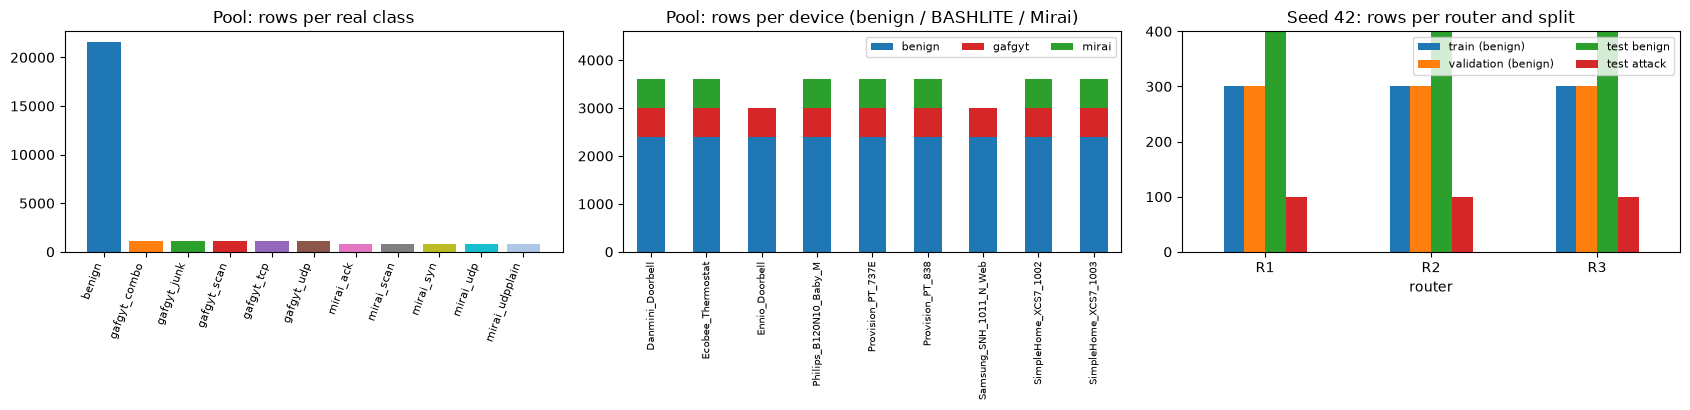

test attack rows per router and real attack type (seed 42):
                R1  R2  R3
label                     
gafgyt_combo    17   7   9
gafgyt_tcp      15  12  11
gafgyt_udp      10   7  15
mirai_syn       10  15  10
mirai_scan       9  11   5
mirai_ack        8  10   5
gafgyt_scan      8   6  13
mirai_udp        8  13   9
mirai_udpplain   7  11   8
gafgyt_junk      7   7  14


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
order_lbl = ["benign"] + sorted(l for l in POOL.label.unique() if l != "benign")
palette = {l: c for l, c in zip(order_lbl, plt.get_cmap("tab20")(np.linspace(0, 1, 20))[[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1]])}
palette["benign"] = "#1f77b4"
c = POOL.groupby("label").size().reindex(order_lbl)
axes[0].bar(range(len(c)), c.values, color=[palette[l] for l in c.index]); axes[0].set_xticks(range(len(c)))
axes[0].set_xticklabels(c.index, rotation=70, ha="right", fontsize=8); axes[0].set_title("Pool: rows per real class")
dv = POOL.groupby(["device", "family"]).size().unstack(fill_value=0)
dv.index = [d.replace("_Security_Camera", "").replace("_WHT", "")[:22] for d in dv.index]
dv.plot.bar(stacked=True, ax=axes[1], color=["#1f77b4", "#d62728", "#2ca02c"]); axes[1].set_title("Pool: rows per device (benign / BASHLITE / Mirai)")
axes[1].tick_params(axis="x", labelsize=7); axes[1].set_ylim(0, 4600); axes[1].legend(ncol=3, fontsize=8, loc="upper right")
tt = []
for r in CLIENTS:
    for k, name in [("train", "train (benign)"), ("val", "validation (benign)"), ("test_b", "test benign"), ("test_a", "test attack")]:
        tt.append(dict(router=r, split=name, rows=len(DS0["D"][r][k])))
tt = pd.DataFrame(tt).pivot(index="router", columns="split", values="rows")[["train (benign)", "validation (benign)", "test benign", "test attack"]]
tt.plot.bar(ax=axes[2], rot=0); axes[2].set_title(f"Seed {SEED}: rows per router and split"); axes[2].set_ylim(0, 400); axes[2].legend(ncol=2, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
print("test attack rows per router and real attack type (seed %d):" % SEED)
print(pd.concat({r: DS0["D"][r]["test_a"].label.value_counts() for r in CLIENTS}, axis=1).fillna(0).astype(int))

### Real observations in two dimensions, coloured by ground-truth label

Top row: the first two **raw PCA coordinates** (PCA fitted on the router's training split; symmetric-log axes because attack traffic lies orders of
magnitude outside the benign cloud). Bottom row: the same two coordinates **scaled to the angles in [0, pi]** that the RY gates of qubits 0 and 1 receive; the
scaler is fitted on benign training rows, so attack points pile up at the borders after clipping. Dots are benign rows (light = training, strong = test),
crosses are attack rows coloured by their true attack type. Benign N-BaIoT traffic is heavy-tailed: for the first seed, one benign R2 test row has `HH_jit_L5_variance` of about 4e17 and therefore lands near 1e14 on PC 1; it is kept (no outlier removal), and the clipping to [0, pi] maps it to the same corner as the attacks.

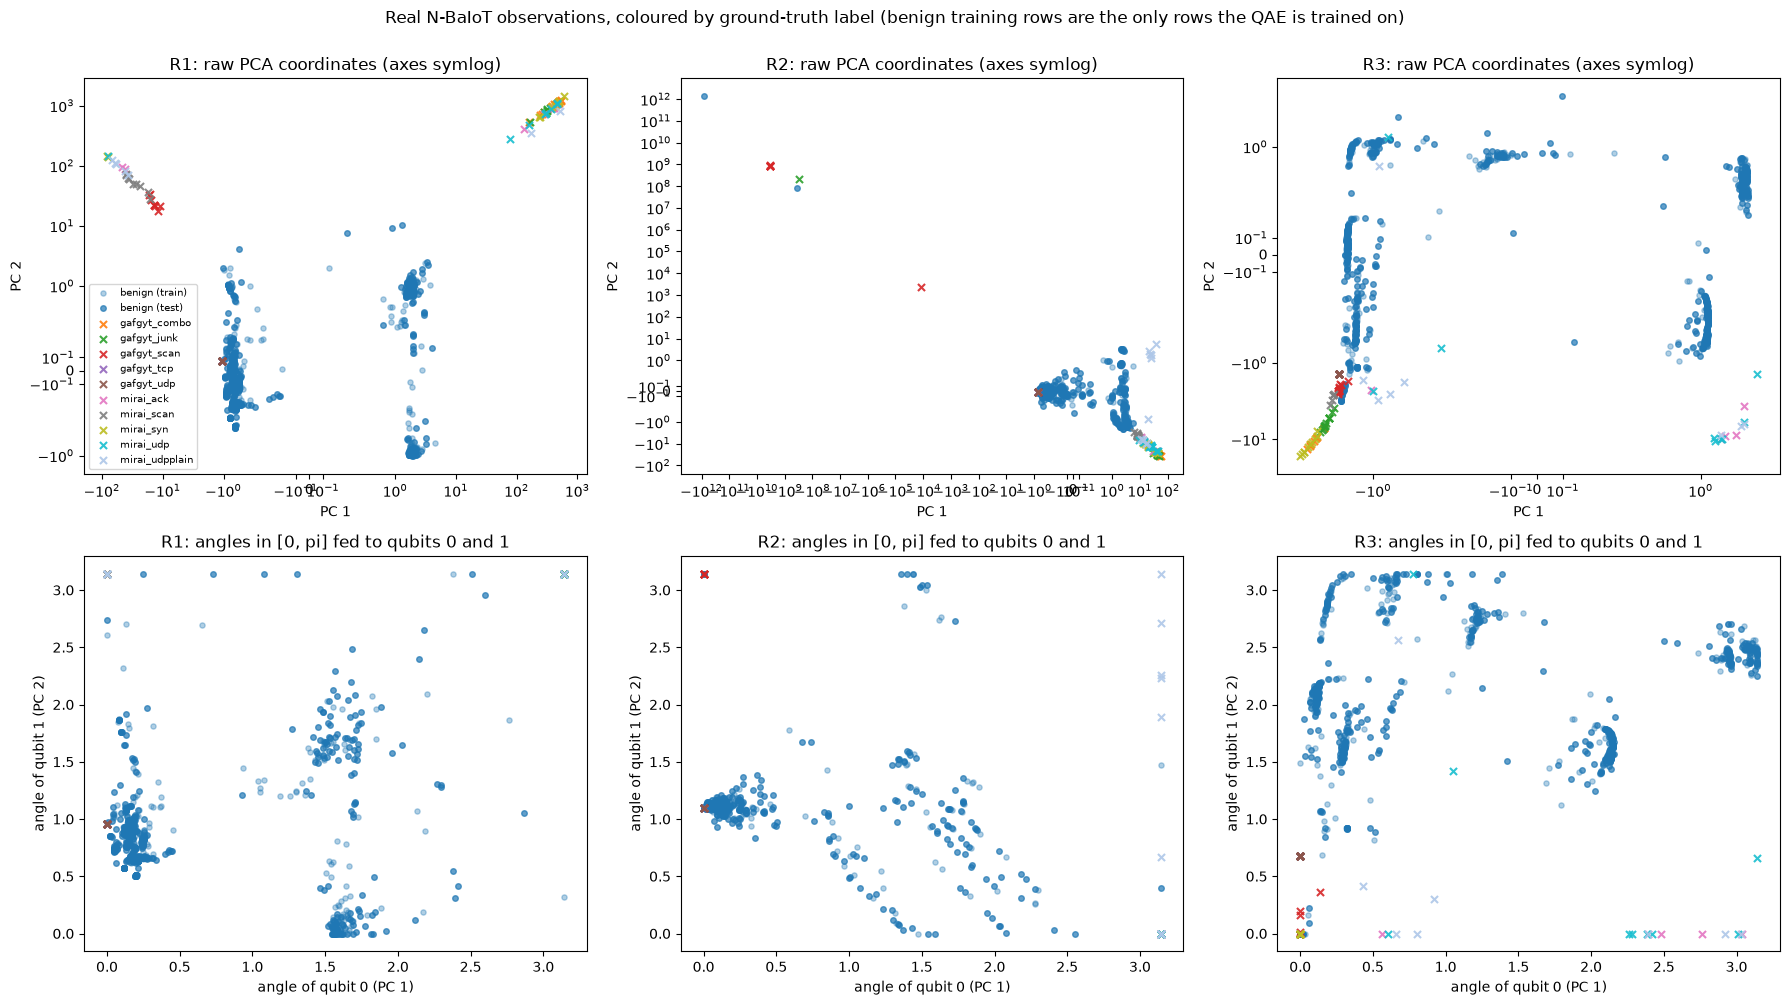

In [8]:
# 2-D scatter of REAL observations coloured by ground-truth label (benign / 5 BASHLITE / 5 Mirai types).
# Row 1: raw coordinates of the first two principal components (PCA fitted on the router's training split only).
# Row 2: the same two coordinates scaled to the RY angles [0, pi] that the quantum circuit receives (test angles clipped).
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, r in enumerate(CLIENTS):
    P_ = DS0["fl_prep"][r]
    layers = [("train", "benign (train)", "o", 14, 0.35), ("test_b", "benign (test)", "o", 16, 0.7), ("test_a", None, "x", 26, 0.9)]
    for row in range(2):
        ax = axes[row, j]
        for k, name, mk, sz, al in layers:
            df = DS0["D"][r][k]
            Z = P_.raw(DS0["X"](df)) if row == 0 else P_.angles(DS0["X"](df))
            for lab in sorted(df.label.unique(), key=lambda l: order_lbl.index(l)):
                m = (df.label == lab).to_numpy()
                ax.scatter(Z[m, 0], Z[m, 1], s=sz, alpha=al, marker=mk, color=palette[lab],
                           label=(name if lab == "benign" else lab) if (name or lab != "benign") else None)
        if row == 0:
            ax.set_xscale("symlog", linthresh=0.5); ax.set_yscale("symlog", linthresh=0.5)
            ax.set_title(f"{r}: raw PCA coordinates (axes symlog)"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
        else:
            ax.set_title(f"{r}: angles in [0, pi] fed to qubits 0 and 1"); ax.set_xlabel("angle of qubit 0 (PC 1)"); ax.set_ylabel("angle of qubit 1 (PC 2)")
        if j == 0 and row == 0:
            h, l_ = ax.get_legend_handles_labels(); seen = {}
            for hh, ll in zip(h, l_):
                seen.setdefault(ll, hh)
            ax.legend(seen.values(), seen.keys(), fontsize=7, loc="lower left")
plt.suptitle("Real N-BaIoT observations, coloured by ground-truth label (benign training rows are the only rows the QAE is trained on)", y=1.0)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The circuit that is executed for every sample (paper Section IV-A and Algorithm 1):

1. **RY angle encoding** of the 10 PCA components, one per qubit (Algorithm 1, line 6).
2. **RealAmplitudes encoder** `U(theta)` (line 7): alternating layers of RY rotations and CX gates (no complex phases, hence "real amplitudes").
3. **Read-out of the 2 trash qubits** (qubits 8, 9). The cost of Eq. (1) is the probability of every outcome except `00`, so `fidelity = P(00)`.

What the paper omits and we chose: the number of RealAmplitudes repetitions (`REPS = 2`, i.e. 3 RY layers and 2 CX ladders, 30 trainable angles), the
entanglement pattern (Qiskit's `reverse_linear`), the position of the trash qubits (the last two, "the last k qubits form the trash subsystem" in Section III),
and that no decoder is run (Eq. 1 needs only the trash statistics).

**How it is simulated.** Training evaluates the loss thousands of times, so the notebook applies *the same gate list* to a whole batch of states with NumPy
(exact probabilities, no shot noise). A cell below asserts that this simulator equals the Qiskit statevector of the drawn circuit to 1e-10, a second cell
checks the shot-based Aer read-out, and a third one shows that a SWAP test on the trash qubits gives the same number.

qubits = 10 (8 latent + 2 trash), classical bits = 2
circuit depth (as drawn) = 16, depth after decompose() = 16
trainable parameters = 30 (RealAmplitudes, reps=2); data-encoding parameters = 10
gate counts: {'r': 40, 'cx': 18, 'barrier': 2, 'measure': 2}


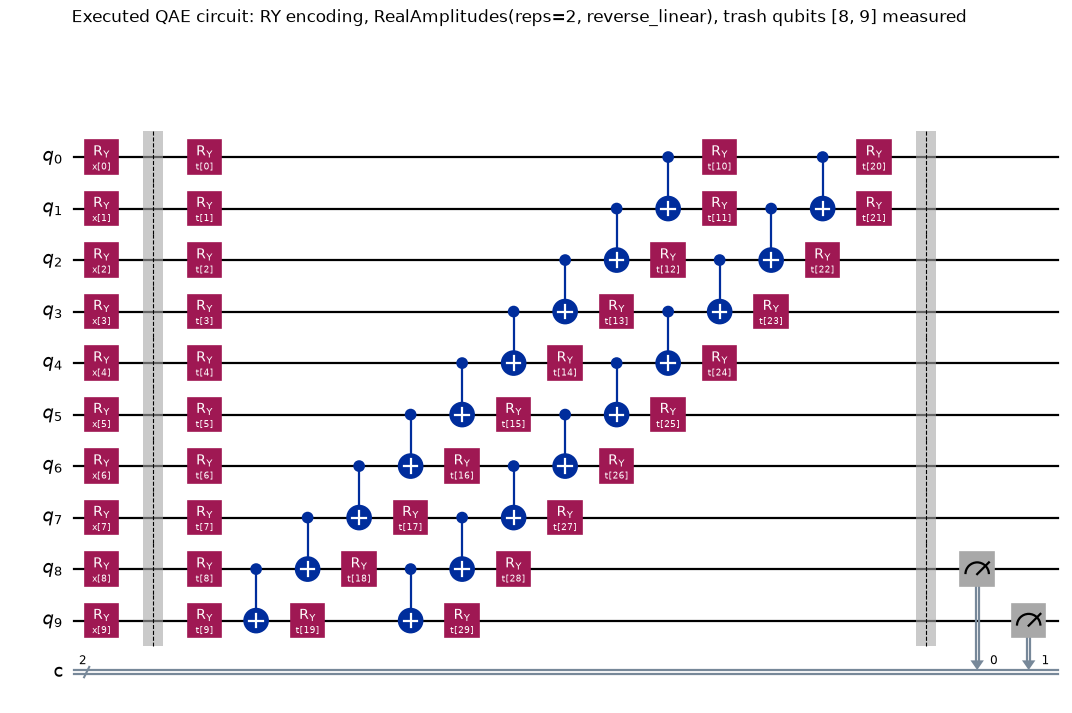

In [9]:
N_PARAMS = (REPS + 1) * N_QUBITS
TRASH = list(range(N_QUBITS - N_TRASH, N_QUBITS))          # the last N_TRASH qubits are the trash subsystem (paper Section III)

def build_executed_circuit(reps=REPS):
    """The circuit the paper describes: RY angle encoding of the 10 PCA features, RealAmplitudes encoder U(theta),
    measurement of the trash qubits (all-zero outcome = 'good')."""
    x = ParameterVector("x", N_QUBITS)
    qc = QuantumCircuit(N_QUBITS, N_TRASH, name="QAE")
    for q in range(N_QUBITS):
        qc.ry(x[q], q)                                       # angle encoding (Algorithm 1, line 6)
    qc.barrier()
    enc = real_amplitudes(N_QUBITS, reps=reps, entanglement=ENTANGLEMENT, parameter_prefix="t")   # CHOICE: reps / entanglement
    qc.compose(enc, inplace=True)                            # RealAmplitudes encoder (Algorithm 1, line 7)
    qc.barrier()
    qc.measure(TRASH, list(range(N_TRASH)))                  # trash-qubit read-out behind Eq. (1)
    return qc, x, enc

qc_exec, X_PARAMS, ENC = build_executed_circuit()
print(f"qubits = {qc_exec.num_qubits} ({N_QUBITS - N_TRASH} latent + {N_TRASH} trash), classical bits = {qc_exec.num_clbits}")
print(f"circuit depth (as drawn) = {qc_exec.depth()}, depth after decompose() = {qc_exec.decompose().depth()}")
print(f"trainable parameters = {ENC.num_parameters} (RealAmplitudes, reps={REPS}); data-encoding parameters = {len(X_PARAMS)}")
print("gate counts:", dict(qc_exec.decompose().count_ops()))
fig = qc_exec.draw("mpl", fold=-1, scale=0.8)
fig.suptitle(f"Executed QAE circuit: RY encoding, RealAmplitudes(reps={REPS}, {ENTANGLEMENT}), trash qubits {TRASH} measured", y=1.02)
display(fig)

### Fast simulator versus the drawn circuit

In [10]:
# --- the fast simulator that trains the model: the same gate list, applied to a batch of states with NumPy ---
DIM = 2 ** N_QUBITS

def _entangle_map(n=N_QUBITS):
    """Basis-state map of the CX ladder of 'reverse_linear' entanglement: CX(n-2,n-1), CX(n-3,n-2), ..., CX(0,1)."""
    mapping = np.arange(2 ** n)
    for c, t in [(q, q + 1) for q in range(n - 2, -1, -1)]:
        mapping = np.where((mapping >> c) & 1, mapping ^ (1 << t), mapping)
    inv = np.empty_like(mapping); inv[mapping] = np.arange(2 ** n)
    return inv
assert ENTANGLEMENT == "reverse_linear", "the NumPy simulator implements the reverse_linear ladder"
PERM = _entangle_map()

def product_states(angles):
    """RY(x_q)|0> on every qubit, batch of states (N, 2^n); qubit q is bit q of the index (Qiskit little-endian)."""
    N = angles.shape[0]; psi = np.ones((N, 1))
    for q in range(N_QUBITS - 1, -1, -1):
        v = np.stack([np.cos(angles[:, q] / 2), np.sin(angles[:, q] / 2)], axis=1)
        psi = (psi[:, :, None] * v[:, None, :]).reshape(N, -1)
    return psi

def _ry(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    return np.array([[c, -s], [s, c]])

def apply_ry_layer(psi, th):
    half = N_QUBITS // 2
    K_lo = np.array([[1.0]]); K_hi = np.array([[1.0]])
    for q in range(half):
        K_lo = np.kron(_ry(th[q]), K_lo)
    for q in range(half, N_QUBITS):
        K_hi = np.kron(_ry(th[q]), K_hi)
    return (K_hi @ psi.reshape(psi.shape[0], 2 ** (N_QUBITS - half), 2 ** half) @ K_lo.T).reshape(psi.shape[0], DIM)

def encoder_state(psi, theta):
    th = np.asarray(theta).reshape(REPS + 1, N_QUBITS)
    psi = apply_ry_layer(psi, th[0])
    for r in range(REPS):
        psi = apply_ry_layer(psi[:, PERM], th[r + 1])
    return psi

def fidelity(psi_in, theta):
    """P(all trash qubits in |0>) = 1 - sum of the 'bad state' probabilities of Eq. (1), for every sample."""
    out = encoder_state(psi_in, theta)
    return (out[:, : DIM >> N_TRASH] ** 2).sum(axis=1)       # trash = the two most significant bits

def loss_eq1(theta, psi_in):
    return 1.0 - fidelity(psi_in, theta).mean()              # Eq. (1): batch mean of the bad-state probability

# --- equivalence check: NumPy simulator == Qiskit statevector of the executed circuit ---
rng_chk = np.random.default_rng(SEED)
Xchk = rng_chk.uniform(0, np.pi, size=(20, N_QUBITS)); th_chk = rng_chk.uniform(*INIT_RANGE, size=N_PARAMS)
unmeasured = qc_exec.remove_final_measurements(inplace=False)
ref = []
for x in Xchk:
    bound = unmeasured.assign_parameters(dict(zip(list(X_PARAMS) + list(ENC.parameters), list(x) + list(th_chk))))
    ref.append(Statevector(bound).probabilities(TRASH)[0])
mine = fidelity(product_states(Xchk), th_chk)
print("max |NumPy - Qiskit Statevector| over 20 random inputs:", np.abs(np.array(ref) - mine).max())
assert np.allclose(ref, mine, atol=1e-10)

max |NumPy - Qiskit Statevector| over 20 random inputs: 4.440892098500626e-16


### The fidelity is really a reconstruction fidelity

The paper thresholds the "reconstruction fidelity". With only the trash measurement available, the natural score is `P(trash = 00)`. The cell below runs the
full compression-decompression circuit with Qiskit (encode, project the trash qubits on `|0..0>`, apply `U^dagger`, compare with the input state) and shows that its fidelity is
**exactly** `P(trash = 00)`: if `phi` is the projected, normalised state, `<psi|U^dagger|phi> = ||P psi_out||` and the fidelity is `||P psi_out||^2`.

In [11]:
# --- why P(trash = 0..0) is the "reconstruction fidelity": compress, reset the trash qubits, decompress, compare with the input ---
def decoder_fidelity(x, theta):
    bound = dict(zip(list(ENC.parameters), list(theta)))
    enc = ENC.assign_parameters(bound)
    psi_in = Statevector(product_states(np.asarray(x)[None, :])[0])
    out = psi_in.evolve(enc).data.copy()
    out[DIM >> N_TRASH:] = 0.0                    # trash qubits forced to |0..0> (post-selection / reset)
    norm = np.linalg.norm(out)
    back = Statevector(out / norm).evolve(enc.inverse())
    return abs(np.vdot(psi_in.data, back.data)) ** 2
dec = np.array([decoder_fidelity(x, th_chk) for x in Xchk[:6]])
print("decoder fidelity :", dec.round(6))
print("P(trash = 0..0)  :", fidelity(product_states(Xchk[:6]), th_chk).round(6))
assert np.allclose(dec, fidelity(product_states(Xchk[:6]), th_chk), atol=1e-9)
print("identical -> the score used for the threshold is exactly the reconstruction fidelity of the compress-reset-decompress circuit.")

decoder fidelity : [0.0639   0.491048 0.037241 0.080802 0.122037 0.029627]
P(trash = 0..0)  : [0.0639   0.491048 0.037241 0.080802 0.122037 0.029627]
identical -> the score used for the threshold is exactly the reconstruction fidelity of the compress-reset-decompress circuit.


### Shot-based read-out and a SWAP test

On a real device the trash probability is estimated from counts. The Aer simulator reproduces the exact value within shot noise. The SWAP-test variant
(ancilla in superposition, controlled swaps of the trash qubits with two fresh `|0>` reference qubits) needs 13 qubits but returns `2 P(ancilla = 0) - 1 = P(trash = 00)`.

   P(trash=00) exact  Aer, 8192 shots  abs. diff
0             0.0639           0.0610     0.0029
1             0.4910           0.4854     0.0057
2             0.0372           0.0349     0.0023
3             0.0808           0.0790     0.0018
4             0.1220           0.1217     0.0003
5             0.0296           0.0281     0.0016
SWAP-test circuit: 13 qubits, depth 15


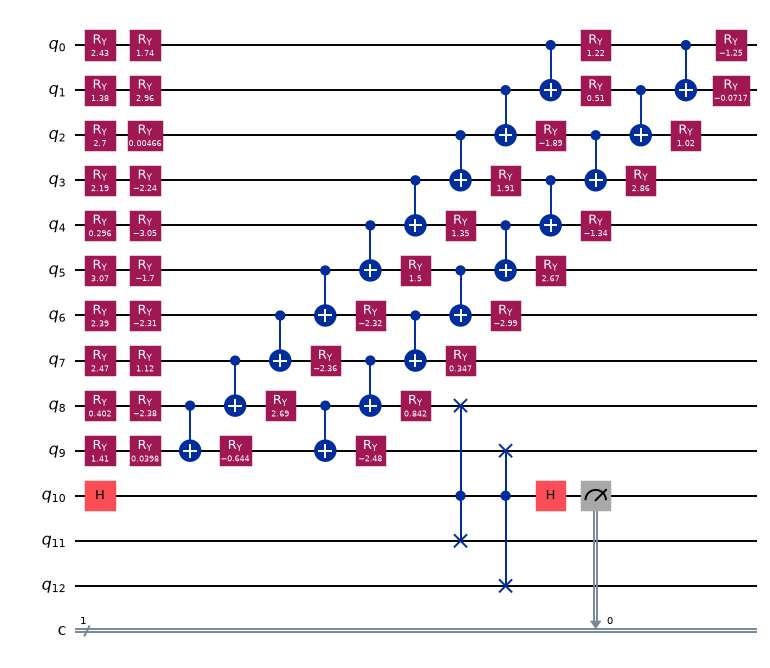

2 P(ancilla=0) - 1 = 0.06390024  vs  P(trash=00) = 0.06390024


In [12]:
# --- shot-based read-out of the same circuit with Qiskit Aer (what real hardware / a sampler would return) ---
SHOTS = 8192
sim = AerSimulator(seed_simulator=SEED)
x_s = Xchk[:6]
est = []
for x in x_s:
    bound = qc_exec.assign_parameters(dict(zip(list(X_PARAMS) + list(ENC.parameters), list(x) + list(th_chk))))
    counts = sim.run(bound, shots=SHOTS).result().get_counts()
    est.append(counts.get("0" * N_TRASH, 0) / SHOTS)
exact = fidelity(product_states(x_s), th_chk)
print(pd.DataFrame({"P(trash=00) exact": exact, f"Aer, {SHOTS} shots": est, "abs. diff": np.abs(exact - est)}).round(4))
assert np.abs(exact - np.array(est)).max() < 4 * 0.5 / np.sqrt(SHOTS) + 1e-3

# --- SWAP-test read-out of the trash overlap with |0..0> (an equivalent alternative to measuring the trash) ---
def swap_test_circuit(x, theta):
    """Ancilla 0 H, controlled-SWAP of each trash qubit with a fresh |0> reference qubit, H, measure the ancilla:
    P(ancilla=0) = (1 + <0..0|rho_trash|0..0>) / 2, so  P(trash=0..0) = 2 P(ancilla=0) - 1."""
    n_ref = N_TRASH
    c = QuantumCircuit(N_QUBITS + 1 + n_ref, 1, name="SWAP test")
    for q in range(N_QUBITS):
        c.ry(float(x[q]), q)
    c.compose(real_amplitudes(N_QUBITS, reps=REPS, entanglement=ENTANGLEMENT).assign_parameters(theta), qubits=range(N_QUBITS), inplace=True)
    anc = N_QUBITS
    c.h(anc)
    for k, tq in enumerate(TRASH):
        c.cswap(anc, tq, N_QUBITS + 1 + k)
    c.h(anc)
    c.measure(anc, 0)
    return c

sw = swap_test_circuit(Xchk[0], th_chk)
print(f"SWAP-test circuit: {sw.num_qubits} qubits, depth {sw.depth()}")
display(sw.draw("mpl", fold=-1, scale=0.7))
p_anc = Statevector(sw.remove_final_measurements(inplace=False)).probabilities([N_QUBITS])[0]
print("2 P(ancilla=0) - 1 =", round(2 * p_anc - 1, 8), " vs  P(trash=00) =", round(float(fidelity(product_states(Xchk[:1]), th_chk)[0]), 8))
assert abs((2 * p_anc - 1) - fidelity(product_states(Xchk[:1]), th_chk)[0]) < 1e-9

## 3. Training: local COBYLA, FedAvg and hierarchical aggregation

- `cobyla` minimises Eq. (1) on a batch with `maxiter` function evaluations, starting from the given parameters.
- `federated_train` is Algorithm 1: in each of the 5 rounds, every router runs 50 COBYLA evaluations on its round's subset, starting from the global parameters; the coordinator then aggregates and broadcasts.
- **FedAvg** averages the three parameter vectors (weighted by the number of rows, i.e. equal weights here).
- **Hierarchical FL** follows the tree of Table I (Scenario I, normal traffic): R3 sends to R2, R1 and R2 send to the coordinator. R2 first averages its parameters with R3's, the coordinator then averages R1 with that result, so the weights are 1/2 (R1), 1/4 (R2), 1/4 (R3). This is our reading of "updates from child nodes are first combined at parent nodes" (the paper gives no formula).
- **Local only** is a reference without federation: each router trains alone with the same budget (5 x 50 evaluations).
- **Centralised** pools and shuffles the training data of all routers and runs 100 COBYLA evaluations, as in the paper.

All four modes of a seed start from the same random initial parameters and use the same split of every router's training set into 5 round subsets.

In [13]:
def cobyla(theta0, psi, iters):
    """Minimise Eq. (1) on the batch `psi` with COBYLA, `iters` function evaluations (what Qiskit's COBYLA(maxiter=iters) calls SciPy for)."""
    hist = []
    def f(th):
        v = loss_eq1(th, psi); hist.append(v); return v
    res = minimize(f, theta0, method="COBYLA", options={"maxiter": iters, "rhobeg": RHOBEG})
    return res.x, hist


def tree_average(theta, node="C"):
    """Hierarchical FL: a parent first averages its own parameters with the (already averaged) parameters of its children;
    the coordinator C has no model of its own and averages its children's results."""
    kids = TOPOLOGY.get(node, [])
    if node == "C":
        return np.mean([tree_average(theta, k) for k in kids], axis=0)
    return np.mean([theta[node]] + [tree_average(theta, k) for k in kids], axis=0)


def aggregate(theta, mode, n_rows):
    if mode == "fedavg":                       # canonical FedAvg: data-size weighted mean (equal sizes here)
        w = np.array([n_rows[r] for r in CLIENTS], dtype=float); w /= w.sum()
        return sum(w[i] * theta[r] for i, r in enumerate(CLIENTS))
    return tree_average(theta)                 # hierarchical FL along TOPOLOGY


def federated_train(PSI, theta0, mode, parts):
    """Algorithm 1: ROUNDS rounds; in each round every router runs LOCAL_ITERS COBYLA steps on its round's subset, starting
    from the global parameters, then the coordinator aggregates and broadcasts."""
    g = theta0.copy(); hist = {r: [] for r in CLIENTS}; round_end = {r: [] for r in CLIENTS}
    n_rows = {r: len(PSI[r]) for r in CLIENTS}
    for t in range(ROUNDS):
        loc = {}
        for r in CLIENTS:
            loc[r], h = cobyla(g, PSI[r][parts[r][t]], LOCAL_ITERS)
            hist[r] += h; round_end[r].append(len(hist[r]))
        g = aggregate(loc, mode, n_rows)
    return g, hist, round_end


def local_only_train(PSI, theta0, parts):
    """No federation: every router trains its own model for ROUNDS x LOCAL_ITERS evaluations on its own data (reference)."""
    out = {}
    for r in CLIENTS:
        th = theta0.copy()
        for t in range(ROUNDS):
            th, _ = cobyla(th, PSI[r][parts[r][t]], LOCAL_ITERS)
        out[r] = th
    return out

## 4. Thresholding and metrics

For each router, the fidelities of its benign **validation** rows give `tau = mu - 4 sigma`; a test row is flagged when its fidelity is below `tau`.
Metrics are the paper's (accuracy and weighted-average precision, recall, F1; recall equals accuracy by construction) with the attack class as positive, plus three
diagnostics the paper does not report: the attack recall, the false-alarm rate on normal traffic, and the threshold-free AUROC of the score `1 - fidelity`.

In [14]:
def weighted_metrics(y, pred, score=None):
    p, r_, f, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    out = dict(accuracy=accuracy_score(y, pred), precision=p, recall=r_, f1=f,
               balanced_acc=balanced_accuracy_score(y, pred),
               attack_recall=float(((pred == 1) & (y == 1)).sum() / max(1, (y == 1).sum())),
               false_alarm=float(((pred == 1) & (y == 0)).sum() / max(1, (y == 0).sum())))
    out["auroc"] = roc_auc_score(y, score) if score is not None else np.nan
    return out


def evaluate_qae(theta, ANG, PSI_cache=None):
    """Per router: fidelities on validation and test, tau = mu - 4 sigma of the validation fidelities, anomaly <=> fidelity < tau."""
    res, det = {}, {}
    for r in CLIENTS:
        f_val = fidelity(product_states(ANG[r]["val"]), theta[r] if isinstance(theta, dict) else theta)
        f_te = fidelity(product_states(ANG[r]["test"]), theta[r] if isinstance(theta, dict) else theta)
        tau = f_val.mean() - TAU_SIGMAS * f_val.std()
        y = DS_CUR["D"][r]["test"].family.ne("benign").astype(int).to_numpy()
        pred = (f_te < tau).astype(int)
        res[r] = weighted_metrics(y, pred, 1 - f_te)
        det[r] = dict(f_val=f_val, f_te=f_te, tau=tau, y=y, pred=pred)
    return res, det


def run_qae_methods(DS, seed, keep=False):
    """Train hierarchical FL, FedAvg, local-only and centralised QAEs from the same initial parameters; evaluate on every router."""
    global DS_CUR
    DS_CUR = DS
    rng = np.random.default_rng(seed)
    theta0 = rng.uniform(*INIT_RANGE, size=N_PARAMS)                  # same initial point for every method
    PSI_FL = {r: product_states(DS["ANG_FL"][r]["train"]) for r in CLIENTS}
    parts = {r: np.array_split(rng.permutation(len(PSI_FL[r])), ROUNDS) for r in CLIENTS}   # train set -> ROUNDS subsets
    out, det, curves = {}, {}, {}
    for mode, name in [("hier", "Hierarchical FL"), ("fedavg", "FedAvg FL")]:
        g, hist, rend = federated_train(PSI_FL, theta0, "fedavg" if mode == "fedavg" else "hier", parts)
        out[name], det[name] = evaluate_qae(g, DS["ANG_FL"]); curves[name] = (hist, rend)
    loc = local_only_train(PSI_FL, theta0, parts)
    out["Local only (no FL)"], det["Local only (no FL)"] = evaluate_qae(loc, DS["ANG_FL"])
    # centralised: pooled and shuffled training data of all routers, one model, CENTRAL_ITERS evaluations
    pooled_train = np.vstack([DS["ANG_C"][r]["train"] for r in CLIENTS])
    pooled_train = pooled_train[rng.permutation(len(pooled_train))]
    g, h = cobyla(theta0, product_states(pooled_train), CENTRAL_ITERS)
    out["Centralized"], det["Centralized"] = evaluate_qae(g, DS["ANG_C"]); curves["Centralized"] = (h, None)
    return out, det, curves


def tidy(out, seed, extra=None):
    rows = []
    for method, per_r in out.items():
        for r, m in per_r.items():
            rows.append(dict(seed=seed, method=method, router=r, **m, **(extra or {})))
    return rows

## 5. Classical references on the same inputs

All references see exactly the angles the centralised quantum model sees (pooled preprocessing, 10 inputs).
**Unsupervised, like the QAE (benign training rows only):** a small autoencoder 10-8-10 with the same 8-dimensional bottleneck (threshold again mean + 4 sigma of the validation
reconstruction error), a one-class SVM and an Isolation Forest. **Supervised (they additionally see labelled attacks, which the QAE never does):** a random forest and an RBF-SVC; they act as a ceiling, not as a fair competitor.

In [15]:
def run_classical(DS, seed):
    """Classical references on EXACTLY the angles the centralised QAE sees (pooled preprocessing, 10 inputs).
    Unsupervised (benign training rows only, like the QAE): small autoencoder 10-8-10 (same bottleneck as 8 latent qubits),
    one-class SVM, Isolation Forest. Supervised (uses attack labels, which the QAE never sees): random forest, RBF-SVC."""
    A = DS["ANG_C"]
    Xtr = np.vstack([A[r]["train"] for r in CLIENTS])
    Xat = np.vstack([A[r]["a_train"] for r in CLIENTS])
    Xsup = np.vstack([Xtr, Xat]); ysup = np.r_[np.zeros(len(Xtr)), np.ones(len(Xat))]
    models = {}
    ae = MLPRegressor(hidden_layer_sizes=(8,), activation="tanh", max_iter=600, random_state=seed).fit(Xtr / np.pi, Xtr / np.pi)
    models["Classical AE (10-8-10)"] = ("ae", ae)
    models["One-class SVM"] = ("score", OneClassSVM(nu=0.05, gamma="scale").fit(Xtr))
    models["Isolation Forest"] = ("score", IsolationForest(random_state=seed).fit(Xtr))
    models["Random forest (supervised)"] = ("sup", RandomForestClassifier(n_estimators=200, random_state=seed).fit(Xsup, ysup))
    models["SVC rbf (supervised)"] = ("sup", SVC(kernel="rbf", probability=False, random_state=seed).fit(Xsup, ysup))
    out = {}
    for name, (kind, mdl) in models.items():
        out[name] = {}
        for r in CLIENTS:
            y = DS["D"][r]["test"].family.ne("benign").astype(int).to_numpy()
            Xv, Xt = A[r]["val"], A[r]["test"]
            if kind == "ae":
                err = lambda Z: ((mdl.predict(Z / np.pi) - Z / np.pi) ** 2).mean(axis=1)
                ev = err(Xv); tau = ev.mean() + TAU_SIGMAS * ev.std()      # same mu +/- 4 sigma rule, on the error instead of the fidelity
                s = err(Xt); pred = (s > tau).astype(int)
            elif kind == "score":
                s = -mdl.decision_function(Xt); pred = (mdl.predict(Xt) == -1).astype(int)
            else:
                s = mdl.decision_function(Xt) if hasattr(mdl, "decision_function") else mdl.predict_proba(Xt)[:, 1]
                pred = mdl.predict(Xt).astype(int)
            out[name][r] = weighted_metrics(y, pred, s)
    return out

In [16]:
# Table II of the paper (accuracy, precision, recall, F1) per router and method.
PAPER = {
    ("R1", "Hierarchical FL"): (0.91, 0.94, 0.91, 0.92), ("R1", "FedAvg FL"): (0.93, 0.94, 0.93, 0.93), ("R1", "Centralized"): (0.88, 0.93, 0.88, 0.90),
    ("R2", "Hierarchical FL"): (0.91, 0.91, 0.91, 0.91), ("R2", "FedAvg FL"): (0.91, 0.91, 0.91, 0.91), ("R2", "Centralized"): (0.91, 0.91, 0.91, 0.91),
    ("R3", "Hierarchical FL"): (0.99, 0.99, 0.99, 0.99), ("R3", "FedAvg FL"): (0.94, 0.96, 0.94, 0.95), ("R3", "Centralized"): (0.99, 0.99, 0.99, 0.99),
}
METRICS = ["accuracy", "precision", "recall", "f1"]

## 6. Run everything

For each seed the notebook draws new train / validation / test rows, a new initial point and a new split of the training sets into round subsets, trains the four quantum modes and the classical references and stores the results.
`FAST_MODE = True`: 2 seeds, 150 training rows per router. `FAST_MODE = False`: 5 seeds, 300 training rows per router.

In [17]:
t_start = time.time()
ALL_Q, ALL_C, DETAIL = [], [], {}
for si in range(N_SEEDS):
    seed = SEED + si
    t0 = time.time()
    DS = DS0 if seed == SEED else make_data(seed)
    out, det, curves = run_qae_methods(DS, seed)
    ALL_Q += tidy(out, seed)
    ALL_C += tidy(run_classical(DS, seed), seed)
    DETAIL[seed] = dict(det=det, curves=curves)
    print(f"seed {seed}: done in {time.time()-t0:.0f}s")
RES_Q, RES_C = pd.DataFrame(ALL_Q), pd.DataFrame(ALL_C)
print(f"total {time.time()-t_start:.0f}s")

seed 42: done in 101s


seed 43: done in 78s


seed 44: done in 70s


seed 45: done in 59s


seed 46: done in 56s
total 364s


## 7. Results of the quantum autoencoders

In [18]:
def fmt(df, cols, group):
    g = df.groupby(group)[cols].agg(["mean", "std"])
    out = pd.DataFrame(index=g.index)
    for c in cols:
        out[c] = [f"{m:.3f} +- {0 if np.isnan(s) else s:.3f}" for m, s in zip(g[c]["mean"], g[c]["std"])]
    return out

M_ORDER = ["Hierarchical FL", "FedAvg FL", "Centralized", "Local only (no FL)"]
print(f"QAE results, mean +- std over {N_SEEDS} seeds (weighted-average precision/recall/F1 as in the paper; attack = positive class)\n")
tab = fmt(RES_Q, ["accuracy", "precision", "recall", "f1", "attack_recall", "false_alarm", "auroc"], ["router", "method"])
tab = tab.reindex([(r, m) for r in CLIENTS for m in M_ORDER])
tab

QAE results, mean +- std over 5 seeds (weighted-average precision/recall/F1 as in the paper; attack = positive class)



accuracy       precision          recall              f1   attack_recall     false_alarm           auroc
router method                                                                                                                            
R1     Hierarchical FL     0.956 +- 0.057  0.932 +- 0.110  0.956 +- 0.057  0.943 +- 0.085  0.737 +- 0.425  0.008 +- 0.005  0.970 +- 0.044
       FedAvg FL           0.958 +- 0.059  0.933 +- 0.112  0.958 +- 0.059  0.945 +- 0.087  0.745 +- 0.430  0.007 +- 0.006  0.971 +- 0.040
       Centralized         0.979 +- 0.025  0.980 +- 0.024  0.979 +- 0.025  0.978 +- 0.027  0.871 +- 0.177  0.003 +- 0.003  0.944 +- 0.109
       Local only (no FL)  0.944 +- 0.057  0.920 +- 0.107  0.944 +- 0.057  0.929 +- 0.083  0.646 +- 0.420  0.007 +- 0.006  0.993 +- 0.010
R2     Hierarchical FL     0.955 +- 0.035  0.957 +- 0.033  0.955 +- 0.035  0.950 +- 0.041  0.715 +- 0.263  0.005 +- 0.003  0.961 +- 0.080
       FedAvg FL           0.945 +- 0.058  0.922 +- 0.108  0.945 +- 0.058  0.929 +- 0.085  0.634 +- 0.426  0.004 +- 0.004  0.961 +- 0.084
       Centralized         0.931 +- 0.071  0.903 +- 0.108  0.931 +- 0.071  0.906 +- 0.103  0.560 +- 0.505  0.008 +- 0.008  0.963 +- 0.063
       Local only (no FL)  0.950 +- 0.052  0.949 +- 0.056  0.950 +- 0.052  0.939 +- 0.073  0.683 +- 0.380  0.006 +- 0.003  0.991 +- 0.014
R3     Hierarchical FL     0.919 +- 0.029  0.915 +- 0.033  0.919 +- 0.029  0.905 +- 0.045  0.485 +- 0.224  0.010 +- 0.003  0.973 +- 0.027
       FedAvg FL           0.934 +- 0.045  0.930 +- 0.050  0.934 +- 0.045  0.922 +- 0.059  0.590 +- 0.315  0.009 +- 0.004  0.979 +- 0.029
       Centralized         0.975 +- 0.020  0.975 +- 0.021  0.975 +- 0.020  0.974 +- 0.022  0.895 +- 0.145  0.012 +- 0.004  0.953 +- 0.097
       Local only (no FL)  0.923 +- 0.054  0.911 +- 0.070  0.923 +- 0.054  0.905 +- 0.074  0.511 +- 0.365  0.009 +- 0.003  0.985 +- 0.014

### Loss curves (the paper's Fig. 4)

The paper shows the training loss of the three routers over the five rounds, with "initial spikes" in the first round. Here are the same curves for the first seed.
Each vertical dotted line is an aggregation step; after it, all routers restart from the same global parameters.

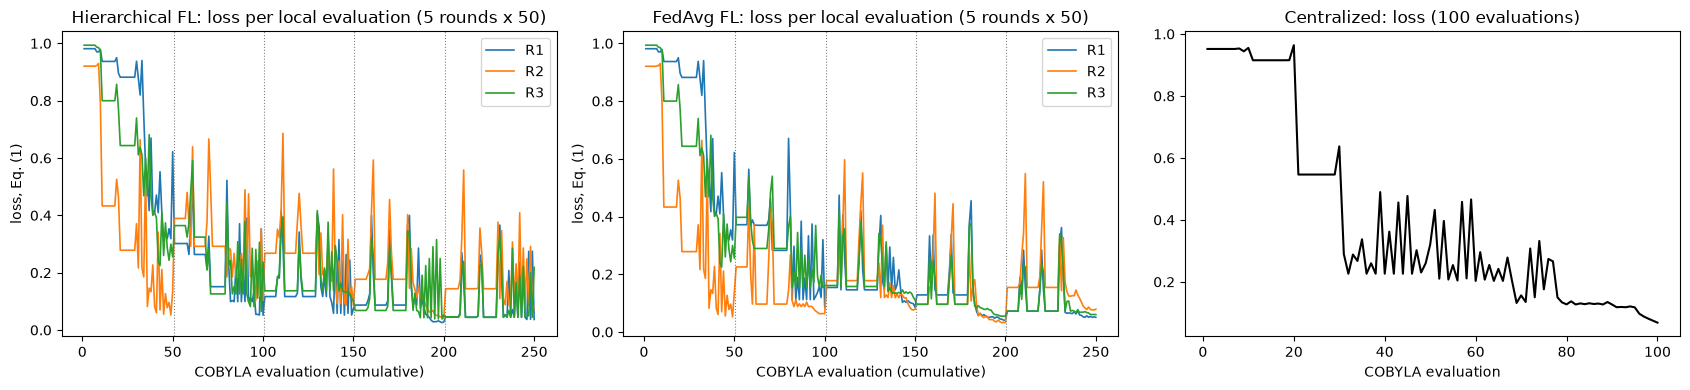

In [19]:
# Re-draw of the paper's Fig. 4: training loss (Eq. 1) of the three routers over the COBYLA evaluations of the 5 rounds (seed = SEED).
cur = DETAIL[SEED]["curves"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes[:2], ["Hierarchical FL", "FedAvg FL"]):
    hist, rend = cur[name]
    for r, c in zip(CLIENTS, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        ax.plot(np.arange(1, len(hist[r]) + 1), hist[r], color=c, lw=1.2, label=r)
    for e in rend[CLIENTS[0]][:-1]:
        ax.axvline(e + 0.5, color="grey", ls=":", lw=0.8)
    ax.set_title(f"{name}: loss per local evaluation ({ROUNDS} rounds x {LOCAL_ITERS})"); ax.set_xlabel("COBYLA evaluation (cumulative)"); ax.set_ylabel("loss, Eq. (1)"); ax.legend()
h, _ = cur["Centralized"]
axes[2].plot(np.arange(1, len(h) + 1), h, color="k"); axes[2].set_title(f"Centralized: loss ({CENTRAL_ITERS} evaluations)"); axes[2].set_xlabel("COBYLA evaluation")
plt.tight_layout(); plt.show()

### Fidelities, threshold and confusion matrices

If the QAE works, benign fidelities are high and attack fidelities low, with a gap that `tau` should fall into.

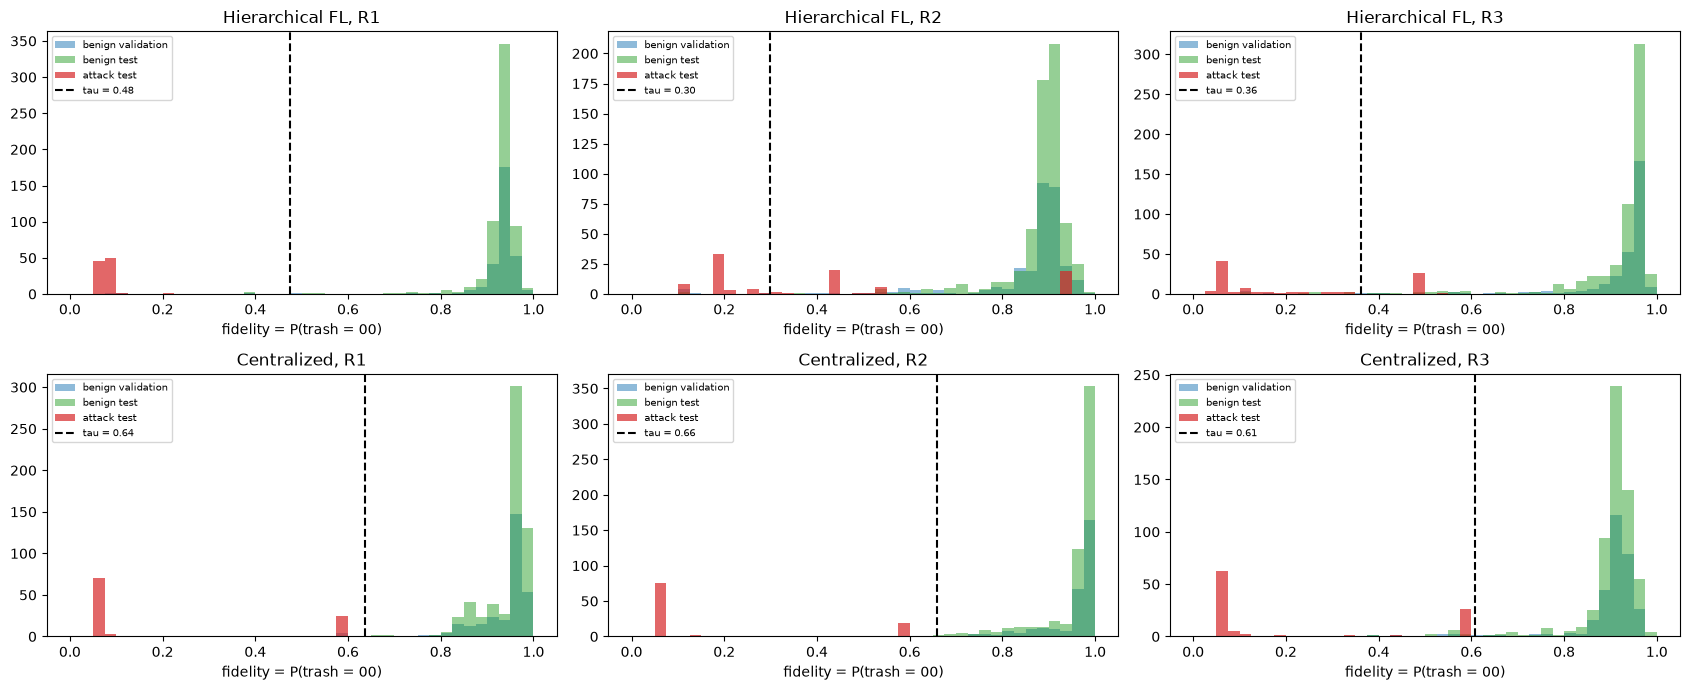

In [20]:
# Fidelity distributions and the threshold tau = mu - 4 sigma (seed = SEED): benign validation, benign test, attack test.
det = DETAIL[SEED]["det"]
fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for i, name in enumerate(["Hierarchical FL", "Centralized"]):
    for j, r in enumerate(CLIENTS):
        d = det[name][r]; ax = axes[i, j]
        bins = np.linspace(0, 1, 41)
        ax.hist(d["f_val"], bins=bins, alpha=0.5, color="#1f77b4", label="benign validation")
        ax.hist(d["f_te"][d["y"] == 0], bins=bins, alpha=0.5, color="#2ca02c", label="benign test")
        ax.hist(d["f_te"][d["y"] == 1], bins=bins, alpha=0.7, color="#d62728", label="attack test")
        ax.axvline(d["tau"], color="k", ls="--", label=f"tau = {d['tau']:.2f}")
        ax.set_title(f"{name}, {r}"); ax.set_xlabel("fidelity = P(trash = 00)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

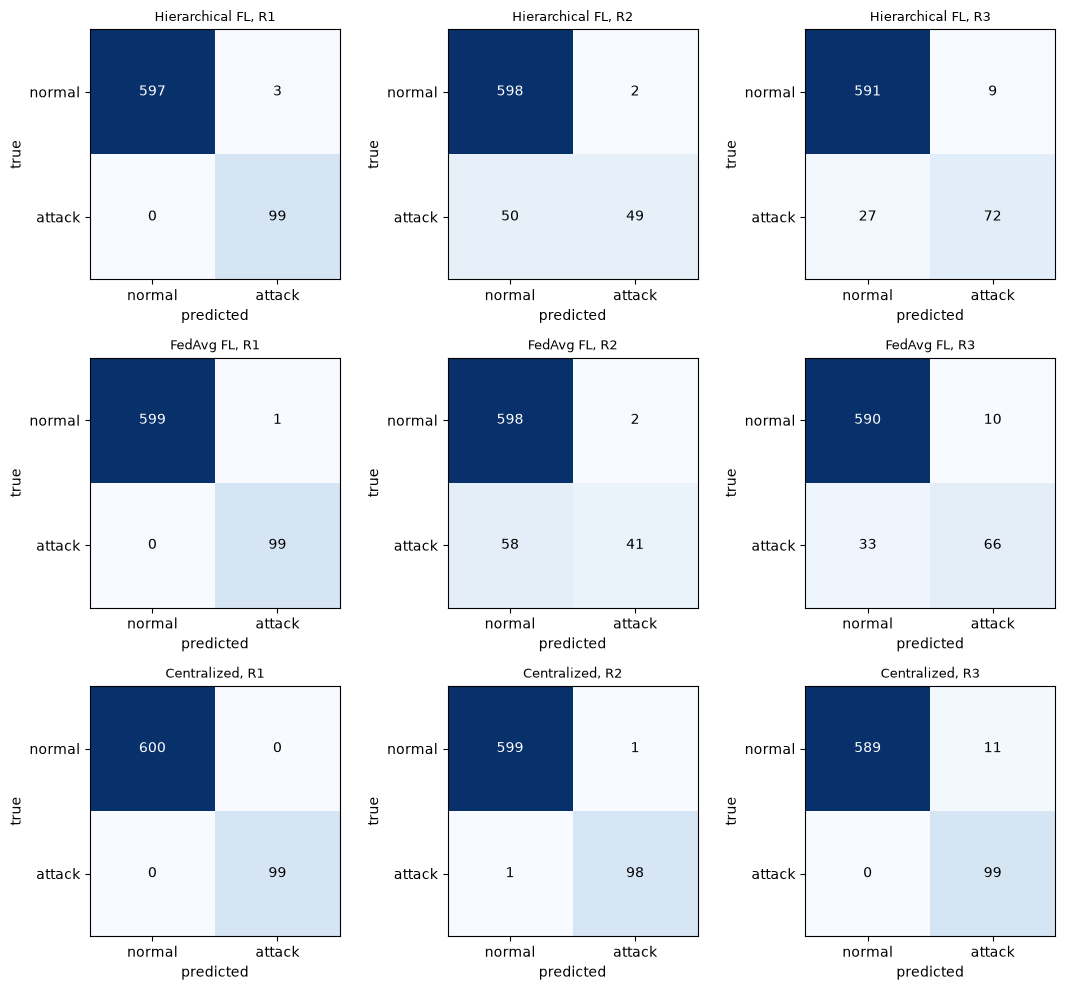

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for i, name in enumerate(["Hierarchical FL", "FedAvg FL", "Centralized"]):
    for j, r in enumerate(CLIENTS):
        d = det[name][r]; cm = confusion_matrix(d["y"], d["pred"], labels=[0, 1]); ax = axes[i, j]
        ax.imshow(cm, cmap="Blues")
        for a in range(2):
            for b in range(2):
                ax.text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "attack"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "attack"])
        ax.set_title(f"{name}, {r}", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

### How much does the "4 sigma" rule cost?

`tau = mu - 4 sigma` is a very conservative cut: it admits almost no false alarms but needs the attack fidelities to drop far below the benign ones. The table shows the F1 for `k = 0..4` in `tau = mu - k sigma`.

In [22]:
# Sensitivity to the threshold rule tau = mu - k sigma (the paper uses k = 4), seed = SEED, weighted F1 and attack recall.
rows = []
for name in ["Hierarchical FL", "FedAvg FL", "Centralized"]:
    for r in CLIENTS:
        d = det[name][r]
        for k in [0, 1, 2, 3, 4]:
            tau = d["f_val"].mean() - k * d["f_val"].std(); pred = (d["f_te"] < tau).astype(int)
            m = weighted_metrics(d["y"], pred, 1 - d["f_te"])
            rows.append(dict(method=name, router=r, k=k, f1=m["f1"], attack_recall=m["attack_recall"], false_alarm=m["false_alarm"]))
sw_ = pd.DataFrame(rows)
print(sw_.pivot_table(index=["method", "router"], columns="k", values="f1").round(3).to_string())
print("\nattack recall:"); print(sw_.pivot_table(index=["method", "router"], columns="k", values="attack_recall").round(3).to_string())

k                           0      1      2      3      4
method          router                                   
Centralized     R1      0.805  0.913  0.992  0.993  1.000
                R2      0.848  0.910  0.958  0.979  0.997
                R3      0.795  0.954  0.971  0.976  0.985
FedAvg FL       R1      0.851  0.976  0.990  0.993  0.999
                R2      0.861  0.930  0.952  0.955  0.899
                R3      0.837  0.943  0.961  0.971  0.935
Hierarchical FL R1      0.850  0.976  0.992  0.993  0.996
                R2      0.870  0.935  0.960  0.920  0.915
                R3      0.838  0.953  0.963  0.979  0.946

attack recall:
k                           0      1      2      3      4
method          router                                   
Centralized     R1      1.000  1.000  1.000  1.000  1.000
                R2      1.000  1.000  0.990  0.990  0.990
                R3      1.000  1.000  1.000  1.000  1.000
FedAvg FL       R1      1.000  1.000  1.000  1.000  1.00

## 8. Classical references

In [23]:
print(f"Classical references on the same 10 angles (centralised, mean +- std over {N_SEEDS} seeds)\n")
ctab = fmt(RES_C, ["accuracy", "f1", "attack_recall", "false_alarm", "auroc"], ["method", "router"])
qtab = fmt(RES_Q[RES_Q.method.isin(["Centralized"])], ["accuracy", "f1", "attack_recall", "false_alarm", "auroc"], ["method", "router"])
qtab.index = pd.MultiIndex.from_tuples([("QAE (centralised, quantum)", r) for _, r in qtab.index])
pd.concat([qtab, ctab])

Classical references on the same 10 angles (centralised, mean +- std over 5 seeds)



accuracy              f1   attack_recall     false_alarm           auroc
QAE (centralised, quantum) R1  0.979 +- 0.025  0.978 +- 0.027  0.871 +- 0.177  0.003 +- 0.003  0.944 +- 0.109
                           R2  0.931 +- 0.071  0.906 +- 0.103  0.560 +- 0.505  0.008 +- 0.008  0.963 +- 0.063
                           R3  0.975 +- 0.020  0.974 +- 0.022  0.895 +- 0.145  0.012 +- 0.004  0.953 +- 0.097
Classical AE (10-8-10)     R1  0.970 +- 0.024  0.968 +- 0.026  0.820 +- 0.167  0.005 +- 0.005  0.982 +- 0.038
                           R2  0.969 +- 0.010  0.967 +- 0.011  0.822 +- 0.106  0.007 +- 0.006  0.979 +- 0.021
                           R3  0.952 +- 0.023  0.951 +- 0.023  0.778 +- 0.128  0.019 +- 0.016  0.946 +- 0.102
Isolation Forest           R1  0.913 +- 0.064  0.919 +- 0.057  0.887 +- 0.156  0.083 +- 0.056  0.977 +- 0.043
                           R2  0.829 +- 0.025  0.850 +- 0.022  0.915 +- 0.117  0.185 +- 0.021  0.969 +- 0.038
                           R3  0.918 +- 0.027  0.923 +- 0.026  0.891 +- 0.150  0.077 +- 0.010  0.936 +- 0.120
One-class SVM              R1  0.967 +- 0.026  0.967 +- 0.027  0.937 +- 0.140  0.028 +- 0.008  0.997 +- 0.005
                           R2  0.923 +- 0.026  0.928 +- 0.024  0.954 +- 0.104  0.082 +- 0.017  0.994 +- 0.010
                           R3  0.922 +- 0.017  0.927 +- 0.017  0.943 +- 0.126  0.082 +- 0.017  0.990 +- 0.009
Random forest (supervised) R1  0.998 +- 0.002  0.998 +- 0.002  0.998 +- 0.005  0.002 +- 0.002  1.000 +- 0.000
                           R2  0.998 +- 0.002  0.998 +- 0.002  0.996 +- 0.009  0.002 +- 0.002  1.000 +- 0.000
                           R3  0.995 +- 0.004  0.995 +- 0.004  0.998 +- 0.005  0.006 +- 0.005  0.999 +- 0.002
SVC rbf (supervised)       R1  0.989 +- 0.018  0.988 +- 0.020  0.935 +- 0.139  0.003 +- 0.002  1.000 +- 0.000
                           R2  0.990 +- 0.014  0.990 +- 0.015  0.947 +- 0.107  0.003 +- 0.002  0.999 +- 0.001
                           R3  0.986 +- 0.016  0.986 +- 0.017  0.943 +- 0.126  0.007 +- 0.005  0.999 +- 0.001

## 9. Side-by-side with the paper

**Table II versus our numbers.** The paper's values come from its private testbed; ours from N-BaIoT. A matching number would be a coincidence, so the per-cell verdict is
"cannot be checked"; the `numerically_close` column only records whether accuracy and F1 happen to lie within 0.02.

In [24]:
mean_ = RES_Q.groupby(["method", "router"])[METRICS].mean()
std_ = RES_Q.groupby(["method", "router"])[METRICS].std().fillna(0)
rows = []
for (r, m), pv in PAPER.items():
    nv = mean_.loc[(m, r)].to_numpy(); sd = std_.loc[(m, r)].to_numpy()
    close = bool(abs(nv[0] - pv[0]) <= 0.02 and abs(nv[3] - pv[3]) <= 0.02)
    rows.append(dict(router=r, method=m,
                     paper_acc=pv[0], nb_acc=f"{nv[0]:.2f}+-{sd[0]:.2f}", paper_prec=pv[1], nb_prec=f"{nv[1]:.2f}+-{sd[1]:.2f}",
                     paper_rec=pv[2], nb_rec=f"{nv[2]:.2f}+-{sd[2]:.2f}", paper_f1=pv[3], nb_f1=f"{nv[3]:.2f}+-{sd[3]:.2f}",
                     dF1=round(nv[3] - pv[3], 2), numerically_close=close,
                     verdict="cannot be checked (private testbed data)"))
cmp_tab = pd.DataFrame(rows)
print("Table II of the paper next to this notebook (substitute data N-BaIoT; mean +- std over seeds)")
print(f"rows whose accuracy and F1 both lie within 0.02 of the paper: {int(cmp_tab.numerically_close.sum())} of {len(cmp_tab)} (coincidence, not a reproduction: the data differ)\n")
cmp_tab

Table II of the paper next to this notebook (substitute data N-BaIoT; mean +- std over seeds)


rows whose accuracy and F1 both lie within 0.02 of the paper: 1 of 9 (coincidence, not a reproduction: the data differ)



,router,method,paper_acc,nb_acc,paper_prec,nb_prec,paper_rec,nb_rec,paper_f1,nb_f1,dF1,numerically_close,verdict
0,R1,Hierarchical FL,0.91,0.96+-0.06,0.94,0.93+-0.11,0.91,0.96+-0.06,0.92,0.94+-0.09,0.02,False,cannot be checked (private testbed data)
1,R1,FedAvg FL,0.93,0.96+-0.06,0.94,0.93+-0.11,0.93,0.96+-0.06,0.93,0.94+-0.09,0.01,False,cannot be checked (private testbed data)
2,R1,Centralized,0.88,0.98+-0.02,0.93,0.98+-0.02,0.88,0.98+-0.02,0.90,0.98+-0.03,0.08,False,cannot be checked (private testbed data)
3,R2,Hierarchical FL,0.91,0.96+-0.03,0.91,0.96+-0.03,0.91,0.96+-0.03,0.91,0.95+-0.04,0.04,False,cannot be checked (private testbed data)
4,R2,FedAvg FL,0.91,0.95+-0.06,0.91,0.92+-0.11,0.91,0.95+-0.06,0.91,0.93+-0.08,0.02,False,cannot be checked (private testbed data)
5,R2,Centralized,0.91,0.93+-0.07,0.91,0.90+-0.11,0.91,0.93+-0.07,0.91,0.91+-0.10,-0.00,False,cannot be checked (private testbed data)
6,R3,Hierarchical FL,0.99,0.92+-0.03,0.99,0.92+-0.03,0.99,0.92+-0.03,0.99,0.90+-0.04,-0.09,False,cannot be checked (private testbed data)
7,R3,FedAvg FL,0.94,0.93+-0.04,0.96,0.93+-0.05,0.94,0.93+-0.04,0.95,0.92+-0.06,-0.03,False,cannot be checked (private testbed data)
8,R3,Centralized,0.99,0.97+-0.02,0.99,0.97+-0.02,0.99,0.97+-0.02,0.99,0.97+-0.02,-0.02,True,cannot be checked (private testbed data)


**Method-level claims that *can* be tested on the substitute.** These are the claims of Section V that do not need the ZigBee redirection attacks: they concern how the
federated and centralised models relate to each other and how the loss behaves. A tolerance of 0.02 (accuracy / F1) is used throughout.

In [25]:
f1 = mean_["f1"]; acc = mean_["accuracy"]
def F(m, r): return float(f1.loc[(m, r)])
def A(m, r): return float(acc.loc[(m, r)])
claims = []
def add(claim, paper, ours, verdict):
    claims.append(dict(claim=claim, paper=paper, this_notebook=ours, verdict=verdict))

# 1. federated ~ centralised (abstract, Section V, conclusion)
for m in ["Hierarchical FL", "FedAvg FL"]:
    d = np.mean([abs(F(m, r) - F("Centralized", r)) for r in CLIENTS])
    add(f"{m} matches centralised training (mean |dF1| over routers)", "paper: 0.007 (hier.), 0.023 (FedAvg)", f"{d:.3f}",
        "reproduced on substitute data" if d <= 0.02 else f"not reached on substitute data (gap {d - 0.02:.3f} above the 0.02 tolerance)")
# 2. FL at least on par with centralised, per router (Section V first paragraph)
for m in ["Hierarchical FL", "FedAvg FL"]:
    worst = min(A(m, r) - A("Centralized", r) for r in CLIENTS)
    add(f"{m} accuracy >= centralised - 0.02 on every router", "paper: all routers (R1 +0.03/+0.05, R2 0, R3 0/-0.05)", f"worst difference {worst:+.3f}",
        "reproduced on substitute data" if worst >= -0.02 else f"not reached on substitute data (worst {worst:+.3f})")
# 3. hierarchical better than FedAvg on R3
d3 = F("Hierarchical FL", "R3") - F("FedAvg FL", "R3")
add("R3: hierarchical FL beats FedAvg (F1 gap)", "paper: 0.99 vs 0.95 (+0.04)", f"{d3:+.3f}",
    "reproduced on substitute data" if d3 >= 0.02 else f"not reached on substitute data (gap {d3:+.3f} < +0.02)")
# 4. FedAvg slightly better on R1
d1 = F("FedAvg FL", "R1") - F("Hierarchical FL", "R1")
add("R1: FedAvg slightly better than hierarchical FL (F1 gap)", "paper: 0.93 vs 0.92 (+0.01)", f"{d1:+.3f}",
    "reproduced on substitute data" if 0.0 <= d1 <= 0.04 else f"not reached on substitute data (gap {d1:+.3f} outside 0..+0.04)")
# 5. R2 all methods equivalent
sp = max(F(m, "R2") for m in M_ORDER[:3]) - min(F(m, "R2") for m in M_ORDER[:3])
add("R2: all three methods perform equivalently (F1 spread)", "paper: 0.91 for all (spread 0.00)", f"{sp:.3f}",
    "reproduced on substitute data" if sp <= 0.02 else f"not reached on substitute data (spread {sp:.3f})")
# 6. absolute level
lo = min(A(m, r) for m in M_ORDER[:2] for r in CLIENTS)
add("federated accuracy between 0.88 and 0.99 on every router", "paper: 0.91-0.99", f"lowest federated accuracy {lo:.3f}",
    "reproduced on substitute data" if lo >= 0.88 else f"not reached on substitute data (lowest {lo:.3f})")
# 7. training loss converges (Fig. 4)
ok, bad = [], []
for seed, dt in DETAIL.items():
    for name in ["Hierarchical FL", "FedAvg FL"]:
        hist, rend = dt["curves"][name]
        for r in CLIENTS:
            h = np.array(hist[r]); good = h[-LOCAL_ITERS:].mean() < h[:LOCAL_ITERS].mean(); ok.append(good)
            if not good:
                bad.append((seed, name, r, round(h[:LOCAL_ITERS].mean(), 3), round(h[-LOCAL_ITERS:].mean(), 3)))
print("curves where the round-5 mean loss is NOT below the round-1 mean (seed, mode, router, round-1 mean, round-5 mean):", bad or "none")
add("training loss is lower in round 5 than in round 1 (Fig. 4, every router, both FL modes, every seed)", "paper: smooth convergence, spike in round 1", f"{int(np.sum(ok))} of {len(ok)} curves",
    "reproduced on substitute data" if all(ok) else "not reached on substitute data")
# 8. things only the private testbed can answer
add("R3 is the easiest router (0.99 for hierarchical / centralised)", "paper: R3 0.99, R1/R2 0.88-0.93", "depends on the traffic of the testbed's routers", "cannot be checked (private testbed data)")
add("redirection attacks via ZigBee AT commands (Table I scenarios I-III) are detected", "paper: Table II", "N-BaIoT contains flooding/scanning botnet attacks, not redirection", "cannot be checked (private testbed data)")
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(claims)

curves where the round-5 mean loss is NOT below the round-1 mean (seed, mode, router, round-1 mean, round-5 mean): [(46, 'Hierarchical FL', 'R1', np.float64(0.147), np.float64(0.229)), (46, 'FedAvg FL', 'R1', np.float64(0.147), np.float64(0.25))]


,claim,paper,this_notebook,verdict
0,Hierarchical FL matches centralised training (mean |dF1| over routers),"paper: 0.007 (hier.), 0.023 (FedAvg)",0.049,not reached on substitute data (gap 0.029 above the 0.02 tolerance)
1,FedAvg FL matches centralised training (mean |dF1| over routers),"paper: 0.007 (hier.), 0.023 (FedAvg)",0.036,not reached on substitute data (gap 0.016 above the 0.02 tolerance)
2,Hierarchical FL accuracy >= centralised - 0.02 on every router,"paper: all routers (R1 +0.03/+0.05, R2 0, R3 0/-0.05)",worst difference -0.056,not reached on substitute data (worst -0.056)
3,FedAvg FL accuracy >= centralised - 0.02 on every router,"paper: all routers (R1 +0.03/+0.05, R2 0, R3 0/-0.05)",worst difference -0.041,not reached on substitute data (worst -0.041)
4,R3: hierarchical FL beats FedAvg (F1 gap),paper: 0.99 vs 0.95 (+0.04),-0.018,not reached on substitute data (gap -0.018 < +0.02)
5,R1: FedAvg slightly better than hierarchical FL (F1 gap),paper: 0.93 vs 0.92 (+0.01),+0.002,reproduced on substitute data
6,R2: all three methods perform equivalently (F1 spread),paper: 0.91 for all (spread 0.00),0.043,not reached on substitute data (spread 0.043)
7,federated accuracy between 0.88 and 0.99 on every router,paper: 0.91-0.99,lowest federated accuracy 0.919,reproduced on substitute data
8,"training loss is lower in round 5 than in round 1 (Fig. 4, every router, both FL modes, every seed)","paper: smooth convergence, spike in round 1",28 of 30 curves,not reached on substitute data
9,R3 is the easiest router (0.99 for hierarchical / centralised),"paper: R3 0.99, R1/R2 0.88-0.93",depends on the traffic of the testbed's routers,cannot be checked (private testbed data)


## 10. Ablation: where is the preprocessing fitted?

The paper says features were computed locally at each router but also that PCA was "fitted on training data". If each router fits its own PCA, the 10 angles mean different things on different routers
and the averaged parameters live in different coordinate systems. The table repeats the quantum runs with the other choice for the first two seeds (`FAST_MODE = False` only).

In [26]:
if RUN_PCA_SCOPE_ABLATION:
    rows_ab = []
    for si in range(min(2, N_SEEDS)):
        seed = SEED + si
        DSg = make_data(seed, pca_scope="global" if PCA_SCOPE == "local" else "local")
        out_g, _, _ = run_qae_methods(DSg, seed)
        rows_ab += tidy(out_g, seed, extra={"scope": "global" if PCA_SCOPE == "local" else "local"})
    ab = pd.DataFrame(rows_ab)
    ref_ = RES_Q[RES_Q.seed.isin(ab.seed.unique())].assign(scope=PCA_SCOPE)
    both = pd.concat([ref_, ab])
    print(both.groupby(["scope", "method", "router"])[["accuracy", "f1", "auroc"]].mean().round(3).unstack("router").to_string())
else:
    print("RUN_PCA_SCOPE_ABLATION is off in FAST_MODE; set FAST_MODE = False to run it.")

                          accuracy                   f1                auroc              
router                          R1     R2     R3     R1     R2     R3     R1     R2     R3
scope  method                                                                             
global Centralized           0.997  0.996  0.988  0.997  0.996  0.988  1.000  0.999  0.997
       FedAvg FL             0.976  0.979  0.974  0.975  0.979  0.972  0.997  0.998  0.997
       Hierarchical FL       0.976  0.979  0.974  0.975  0.979  0.972  0.999  0.998  0.997
       Local only (no FL)    0.997  0.991  0.923  0.997  0.991  0.900  1.000  0.998  0.991
local  Centralized           0.997  0.996  0.988  0.997  0.996  0.988  1.000  0.999  0.997
       FedAvg FL             0.996  0.954  0.966  0.996  0.946  0.964  1.000  0.904  0.993
       Hierarchical FL       0.994  0.959  0.941  0.994  0.954  0.937  0.999  0.908  0.974
       Local only (no FL)    0.994  0.929  0.964  0.994  0.904  0.962  1.000  0.981  0.993

In the committed full run (2 seeds) the choice matters: with one **global** preprocessor the federated models reach accuracy 0.97-0.98 on every router, with **local** preprocessors 0.94-1.00 and a clear drop on R2 (AUROC about 0.90, against 0.998). That is the effect the paragraph above predicts: averaged parameters only make sense when all routers feed the circuit the same coordinate system. The paper does not say which of the two it used, and a federated setting in which a global PCA is fitted on pooled raw data defeats part of its privacy argument.

## 11. Reading the paper critically

- **The data cannot be checked.** All numbers in Table II come from one private testbed, one run, one split; there are no seeds, confidence intervals or a significance test, although the abstract says "statistically indistinguishable". Differences of 0.01-0.05 between methods (R1, R3) are within what a few hundred test windows can produce; our multi-seed standard deviations show how large that noise is.
- **No classical or unfederated baseline.** The paper compares federated with centralised quantum training only. It never shows that a *quantum* autoencoder is needed: a classical 10-8-10 autoencoder, a one-class SVM or an Isolation Forest on the same inputs (section 8) set the reference that a quantum claim has to beat, and no "local only" model shows what federation adds (see the `Local only` rows).
- **"Quantum advantage in pattern recognition"** (abstract) is not tested. The model is simulated exactly on 10 qubits; with a product-state input and a shallow RealAmplitudes circuit it is cheap to simulate classically and has 30 parameters.
- **Under-specified optimisation.** COBYLA with 50 *iterations* is 50 function evaluations in SciPy and Qiskit; for 30 or more parameters the first n + 1 evaluations only build the initial simplex, so a round is a few actual steps. This is probably what the "initial spikes" of Fig. 4 show. Centralised training gets 100 evaluations on all data, federated training 250 per router, so the two are not budget-matched.
- **Thresholding.** `tau = mu - 4 sigma` assumes roughly Gaussian benign fidelities; with a small validation set one outlier moves `tau` a lot (see the histograms and the sweep). The paper does not justify the factor 4 or report how it was chosen.
- **Hierarchical versus FedAvg.** The paper concludes that hierarchical aggregation "captures local variations and inter-node dependencies" from one router (R3), while FedAvg wins on R1 and the methods tie on R2. With three clients and no repeated runs this is not evidence for a mechanism. In our reading the tree only changes the *weights* (1/2, 1/4, 1/4 instead of 1/3 each).
- **Metrics.** Weighted averaging over a 6 : 1 normal : attack test set lets a detector that flags nothing reach an accuracy of about 0.86; recall equal to accuracy hides the real attack recall. Report the attack-class recall, false-alarm rate and a threshold-free score such as AUROC, as done here.
- **Fidelity.** The text speaks of reconstruction fidelity while Eq. (1) only needs the trash statistics; we show they are the same number for a projected decoder.

## 12. Exercises

1. **Repetitions.** Set `REPS = 1` and `REPS = 3` (the simulator reads `REPS`). How do the loss curves and the F1 change? Is 50 COBYLA evaluations enough for 40 parameters?
2. **Threshold.** Replace `TAU_SIGMAS = 4` by 2 or 3 and compare attack recall and false-alarm rate. Which `k` would you pick using only the validation set?
3. **Hierarchy.** Change `TOPOLOGY` to Scenario II/III of Table I (`{"C": ["R1", "R2", "R3"]}`). Is hierarchical FL then identical to FedAvg? Try a deeper chain `R3 -> R2 -> R1 -> C`.
4. **Heterogeneity.** Put one single device type in each router (for example all cameras in R2) or give R3 only Mirai-free devices. When does the global model stop helping a router?
5. **Quantum or not.** Replace the QAE by the classical 10-8-10 autoencoder inside the same federated loop (average the weights of three `MLPRegressor`s) and compare with the QAE under the same communication budget.